# Cohort Revenue & Retention Modeling Example

**Author:** [Juan Orduz](https://juanitorduz.github.io/)

In this notebook we implement a variation of the cohort model presented in the pre-print ["Cohort Revenue & Retention Analysis: A Bayesian Approach"](https://arxiv.org/abs/2504.16216) (code [here](https://juanitorduz.github.io/revenue_retention/)) for a sample data kindly provided by [Bruce Hardie](https://www.brucehardie.com/).

## Prepare Notebook

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import pymc as pm
import pymc_bart as pmb
import pytensor.tensor as pt
import seaborn as sns
from pymc_bart.split_rules import ContinuousSplitRule, SubsetSplitRule
from pymc_marketing.metrics import crps
from scipy.special import expit, logit
from sklearn.preprocessing import LabelEncoder, MaxAbsScaler

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

In [2]:
seed: int = sum(map(ord, "cohort_modeling"))
rng: np.random.Generator = np.random.default_rng(seed=seed)

## Read Data

We read the matrices provided in an excel file.

In [3]:
data_path = "../data/cohort_tables_for_juan.xlsx"

number_of_customers_raw = pd.read_excel(
    data_path,
    "All cohorts -- combined",
    index_col=0,
    usecols="A:Q",
    skiprows=2,
    nrows=18,
)

number_of_customers_raw

,y2016_q1,y2016_q2,y2016_q3,y2016_q4,y2017_q1,y2017_q2,y2017_q3,y2017_q4,y2018_q1,y2018_q2,y2018_q3,y2018_q4,y2019_q1,y2019_q2,y2019_q3,y2019_q4
pre_y2016,2010.0,1908.0,1859.0,3062.0,1515.0,1692.0,1470.0,2501.0,1408.0,1549.0,1435.0,2391.0,1287.0,1375.0,1366.0,2241
y2016_q1,2944.0,355.0,326.0,481.0,299.0,277.0,236.0,372.0,262.0,251.0,248.0,382.0,221.0,216.0,218.0,341
y2016_q2,NaN,2969.0,433.0,519.0,273.0,329.0,272.0,379.0,245.0,286.0,257.0,371.0,205.0,243.0,215.0,321
y2016_q3,NaN,NaN,2842.0,549.0,243.0,297.0,305.0,370.0,212.0,261.0,251.0,348.0,188.0,233.0,241.0,315
y2016_q4,NaN,NaN,NaN,6162.0,620.0,550.0,458.0,953.0,438.0,431.0,409.0,838.0,361.0,375.0,337.0,762
y2017_q1,NaN,NaN,NaN,NaN,2459.0,269.0,211.0,331.0,216.0,173.0,175.0,292.0,178.0,172.0,160.0,265
y2017_q2,NaN,NaN,NaN,NaN,NaN,2236.0,280.0,320.0,181.0,217.0,197.0,276.0,166.0,181.0,169.0,241
y2017_q3,NaN,NaN,NaN,NaN,NaN,NaN,2143.0,389.0,218.0,222.0,239.0,282.0,160.0,184.0,202.0,254
y2017_q4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5888.0,628.0,430.0,406.0,928.0,370.0,344.0,348.0,777
y2018_q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2693.0,292.0,253.0,387.0,245.0,229.0,204.0,339


In [4]:
total_spend_raw = pd.read_excel(
    data_path,
    "All cohorts -- combined",
    index_col=0,
    usecols="A:Q",
    skiprows=68,
    nrows=18,
)

total_spend_raw

,y2016_q1,y2016_q2,y2016_q3,y2016_q4,y2017_q1,y2017_q2,y2017_q3,y2017_q4,y2018_q1,y2018_q2,y2018_q3,y2018_q4,y2019_q1,y2019_q2,y2019_q3,y2019_q4
pre_y2016,146469.72,147472.24,122340.91,262104.03,113694.80,114756.79,97574.81,210861.60,95459.96,104314.94,90077.47,198903.35,97135.11,93293.45,88732.57,191090.54
y2016_q1,183054.91,26705.56,19814.07,41003.87,20687.20,18606.73,13196.78,30292.31,17879.51,15101.83,14645.92,28513.02,16074.13,15220.93,13931.42,25092.79
y2016_q2,NaN,173538.95,28257.96,44169.41,20847.86,21766.06,17495.31,29636.76,18373.08,18129.28,15259.08,30552.06,12818.48,15896.97,12256.13,22144.01
y2016_q3,NaN,NaN,169801.16,44607.95,17704.73,17696.39,19498.53,31182.84,12873.41,16901.40,15046.24,26502.08,11249.28,14747.00,14481.31,23655.59
y2016_q4,NaN,NaN,NaN,462570.46,46512.25,32395.31,28449.73,85700.87,29531.04,24698.80,22408.81,63535.72,25290.76,21524.64,20035.82,63588.12
y2017_q1,NaN,NaN,NaN,NaN,167251.29,16951.59,13121.43,26874.17,14975.41,11088.31,9605.31,25119.04,10957.68,11266.06,8627.77,20766.34
y2017_q2,NaN,NaN,NaN,NaN,NaN,133107.46,15825.43,23227.19,12293.93,13046.55,13820.91,18743.83,11698.33,12678.44,11880.58,16908.91
y2017_q3,NaN,NaN,NaN,NaN,NaN,NaN,128553.35,27355.14,14951.89,12157.69,15006.42,20302.66,11401.45,10490.93,11331.99,17979.52
y2017_q4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,412403.83,40881.56,24377.49,23002.82,72807.97,25975.14,20362.67,20105.69,61710.57
y2018_q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,162871.13,18487.83,14952.24,28817.37,13959.85,13998.13,11282.79,27512.44


## Data Cleaning

Next, we do some data cleaning and formatting to get the data in the required shape (we also keep the same names for the variables as in the pre-print).


In [5]:
number_of_customers_wide = (
    number_of_customers_raw.reset_index(drop=False)
    .rename(columns={"index": "cohort"})
    .query("cohort != 'pre_y2016'")
)


def _clean_cohort_name(cohort_name: pd.Series) -> pd.Series:
    cohort_name_clean = (
        cohort_name.str.replace("y", "").str.replace("_", "-").str.replace("q", "Q")
    )
    return pd.PeriodIndex(cohort_name_clean, freq="Q").to_timestamp()


number_of_customers_long = (
    number_of_customers_wide.melt(
        id_vars="cohort", var_name="period", value_name="n_active_users"
    )
    .query("n_active_users.notna()")
    .sort_values(by=["cohort", "period"])
    .assign(
        cohort_date=lambda df: _clean_cohort_name(df["cohort"]),
        period_date=lambda df: _clean_cohort_name(df["period"]),
        n_active_users=lambda df: df["n_active_users"].astype(int),
        n_users=lambda df: df.groupby("cohort")["n_active_users"]
        .transform("max")
        .astype(int),
    )
    .assign(
        age=lambda df: (df["period_date"].max() - df["period_date"]).dt.days,
        cohort_quarter=lambda df: df["cohort_date"].dt.quarter,
        period_quarter=lambda df: df["period_date"].dt.quarter,
        cohort_age=lambda df: (df["period_date"] - df["cohort_date"]).dt.days,
        retention=lambda df: df["n_active_users"] / df["n_users"],
    )
)

number_of_customers_long.head()

,cohort,period,n_active_users,cohort_date,period_date,n_users,age,cohort_quarter,period_quarter,cohort_age,retention
0,y2016_q1,y2016_q1,2944,2016-01-01,2016-01-01,2944,1369,1,1,0,1.000000
16,y2016_q1,y2016_q2,355,2016-01-01,2016-04-01,2944,1278,1,2,91,0.120584
32,y2016_q1,y2016_q3,326,2016-01-01,2016-07-01,2944,1187,1,3,182,0.110734
48,y2016_q1,y2016_q4,481,2016-01-01,2016-10-01,2944,1095,1,4,274,0.163383
64,y2016_q1,y2017_q1,299,2016-01-01,2017-01-01,2944,1003,1,1,366,0.101562


In [6]:
total_spend_wide = (
    total_spend_raw.reset_index(drop=False)
    .rename(columns={"index": "cohort"})
    .query("cohort != 'pre_y2016'")
)

total_spend_long = (
    total_spend_wide.melt(id_vars="cohort", var_name="period", value_name="revenue")
    .query("revenue.notna()")
    .sort_values(by=["cohort", "period"])
)

total_spend_long.head()

,cohort,period,revenue
0,y2016_q1,y2016_q1,183054.91
16,y2016_q1,y2016_q2,26705.56
32,y2016_q1,y2016_q3,19814.07
48,y2016_q1,y2016_q4,41003.87
64,y2016_q1,y2017_q1,20687.20


In [7]:
data_df = number_of_customers_long.merge(
    total_spend_long, on=["cohort", "period"], how="inner"
)

data_df.head()

,cohort,period,n_active_users,cohort_date,period_date,n_users,age,cohort_quarter,period_quarter,cohort_age,retention,revenue
0,y2016_q1,y2016_q1,2944,2016-01-01,2016-01-01,2944,1369,1,1,0,1.000000,183054.91
1,y2016_q1,y2016_q2,355,2016-01-01,2016-04-01,2944,1278,1,2,91,0.120584,26705.56
2,y2016_q1,y2016_q3,326,2016-01-01,2016-07-01,2944,1187,1,3,182,0.110734,19814.07
3,y2016_q1,y2016_q4,481,2016-01-01,2016-10-01,2944,1095,1,4,274,0.163383,41003.87
4,y2016_q1,y2017_q1,299,2016-01-01,2017-01-01,2944,1003,1,1,366,0.101562,20687.20


## Exploratory Data Analysis

Now we can perform an analogous analysis to the one presented in the pre-print and the code notebook. This is crucial to define the modeling strategy.

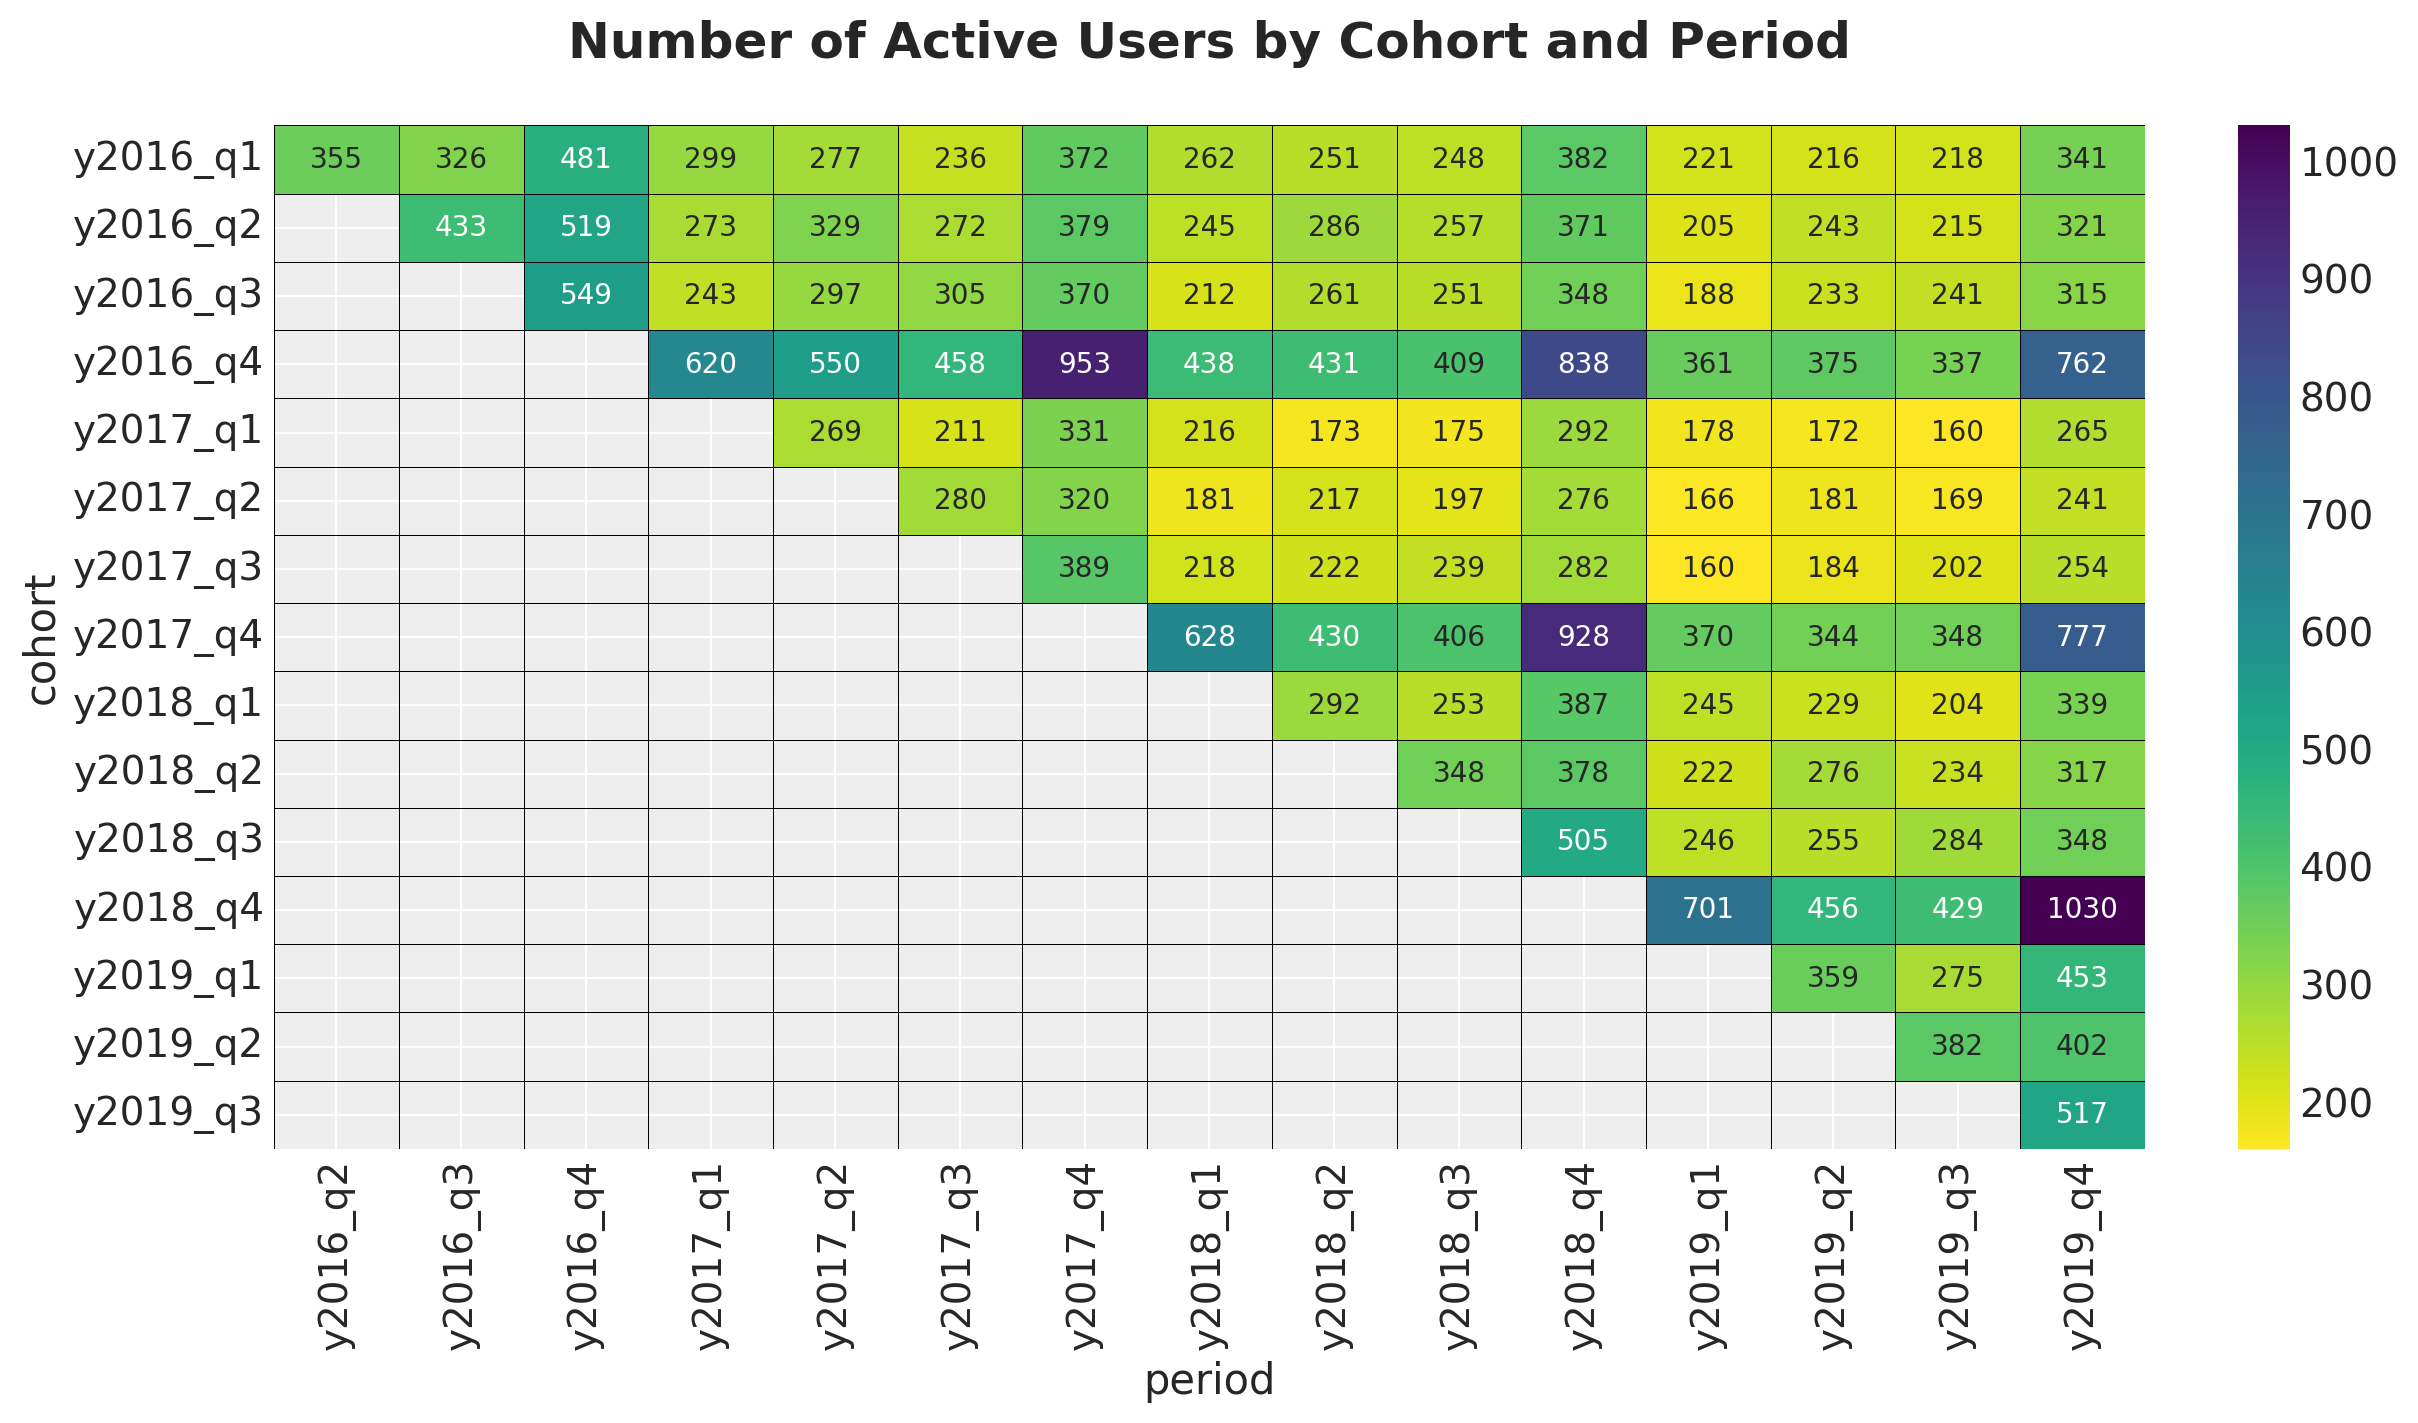

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

(
    data_df.query("cohort_age != 0")
    .filter(["cohort", "period", "n_active_users"])
    .pivot_table(index="cohort", columns="period", values="n_active_users")
    .pipe(
        (sns.heatmap, "data"),
        cmap="viridis_r",
        linewidths=0.2,
        linecolor="black",
        annot=True,
        fmt="0.0f",
        ax=ax,
    )
)

ax.set_title(
    "Number of Active Users by Cohort and Period",
    fontsize=18,
    fontweight="bold",
    y=1.05,
);

We see a clear seasonal pattern in the number of active users at the cohort and period levels. This hints that we need to add these two variables to the model (as opposed to the pre-print where only the period seasonal effect was considered).

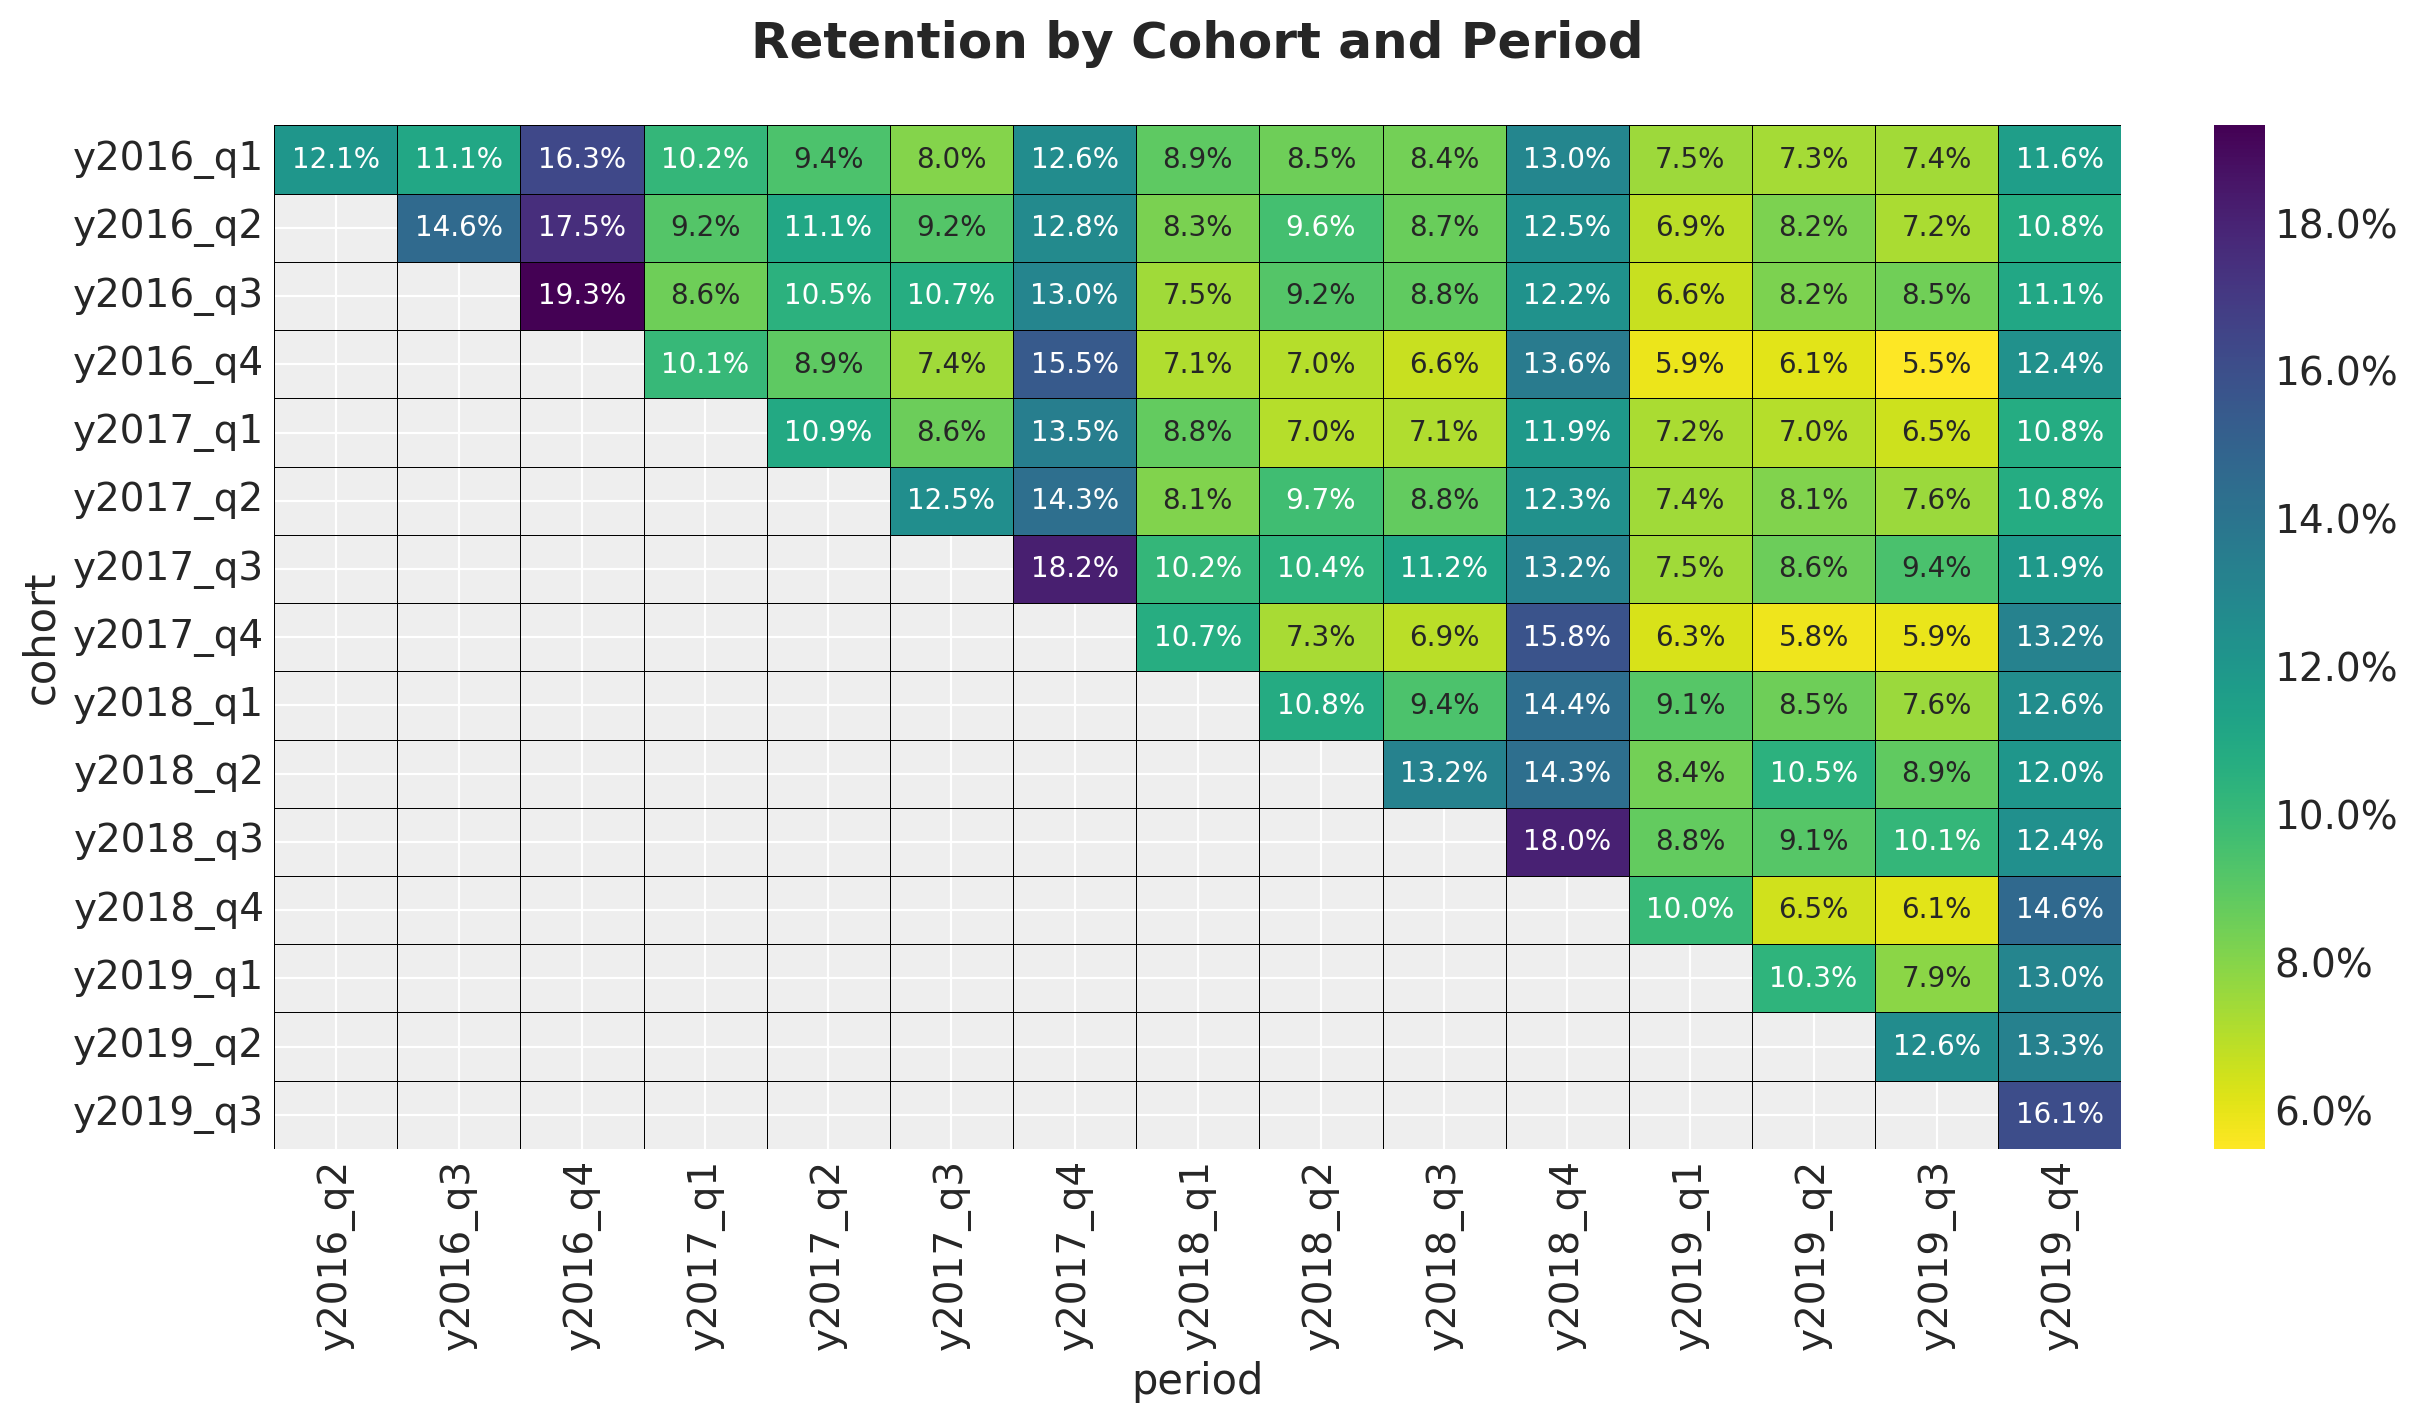

In [9]:
fig, ax = plt.subplots(figsize=(12, 7))

(
    data_df.query("cohort_age != 0")
    .filter(["cohort", "period", "retention"])
    .pivot_table(index="cohort", columns="period", values="retention")
    .pipe(
        (sns.heatmap, "data"),
        cmap="viridis_r",
        linewidths=0.2,
        linecolor="black",
        annot=True,
        fmt="0.1%",
        cbar_kws={"format": mtick.PercentFormatter(1)},
        ax=ax,
    )
)

ax.set_title(
    "Retention by Cohort and Period",
    fontsize=18,
    fontweight="bold",
    y=1.05,
);

At the retention level we also see both of these seasonal patterns. Moreover, the period seasonal effect across cohorts is very smooth, so here the BART model can help us capture this effect with the non-parametric flexibility.

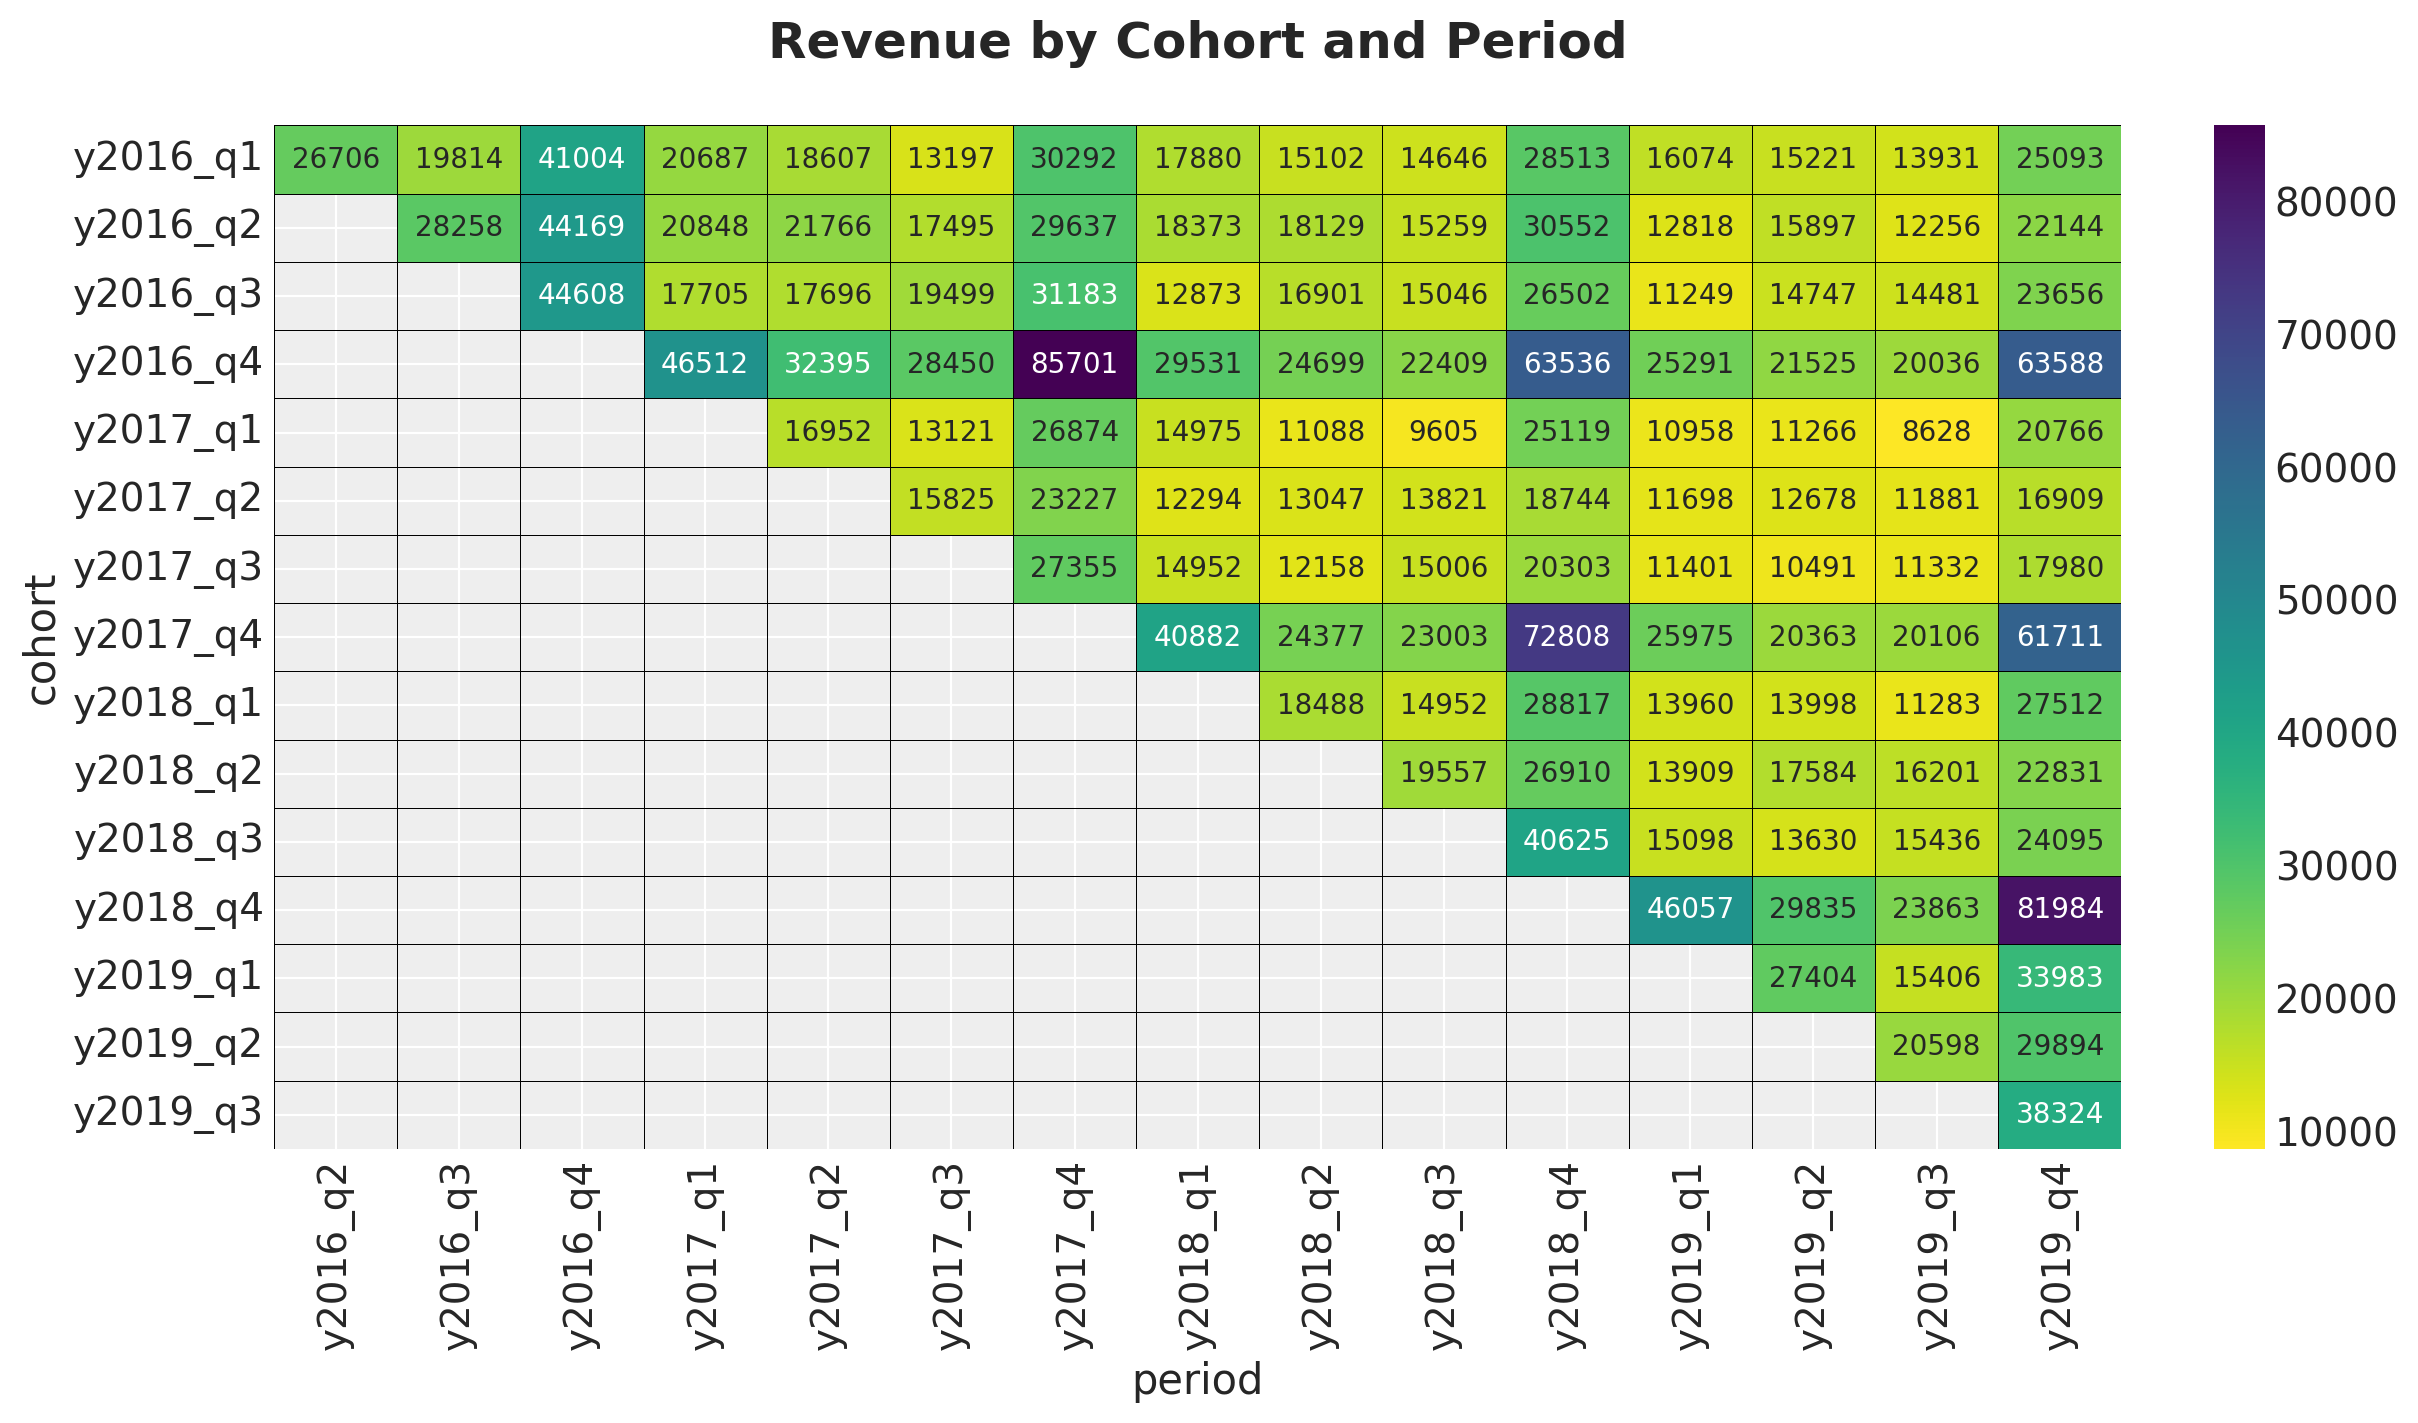

In [10]:
fig, ax = plt.subplots(figsize=(12, 7))

(
    data_df.query("cohort_age != 0")
    .filter(["cohort", "period", "revenue"])
    .pivot_table(index="cohort", columns="period", values="revenue")
    .pipe(
        (sns.heatmap, "data"),
        cmap="viridis_r",
        linewidths=0.2,
        linecolor="black",
        annot=True,
        fmt="0.0f",
        ax=ax,
    )
)

ax.set_title(
    "Revenue by Cohort and Period",
    fontsize=18,
    fontweight="bold",
    y=1.05,
);

The revenue matrix shows a combination of the number of active users and the retention rates. Thus, the coupling mechanism of the model seems to be a very reasonable approach.

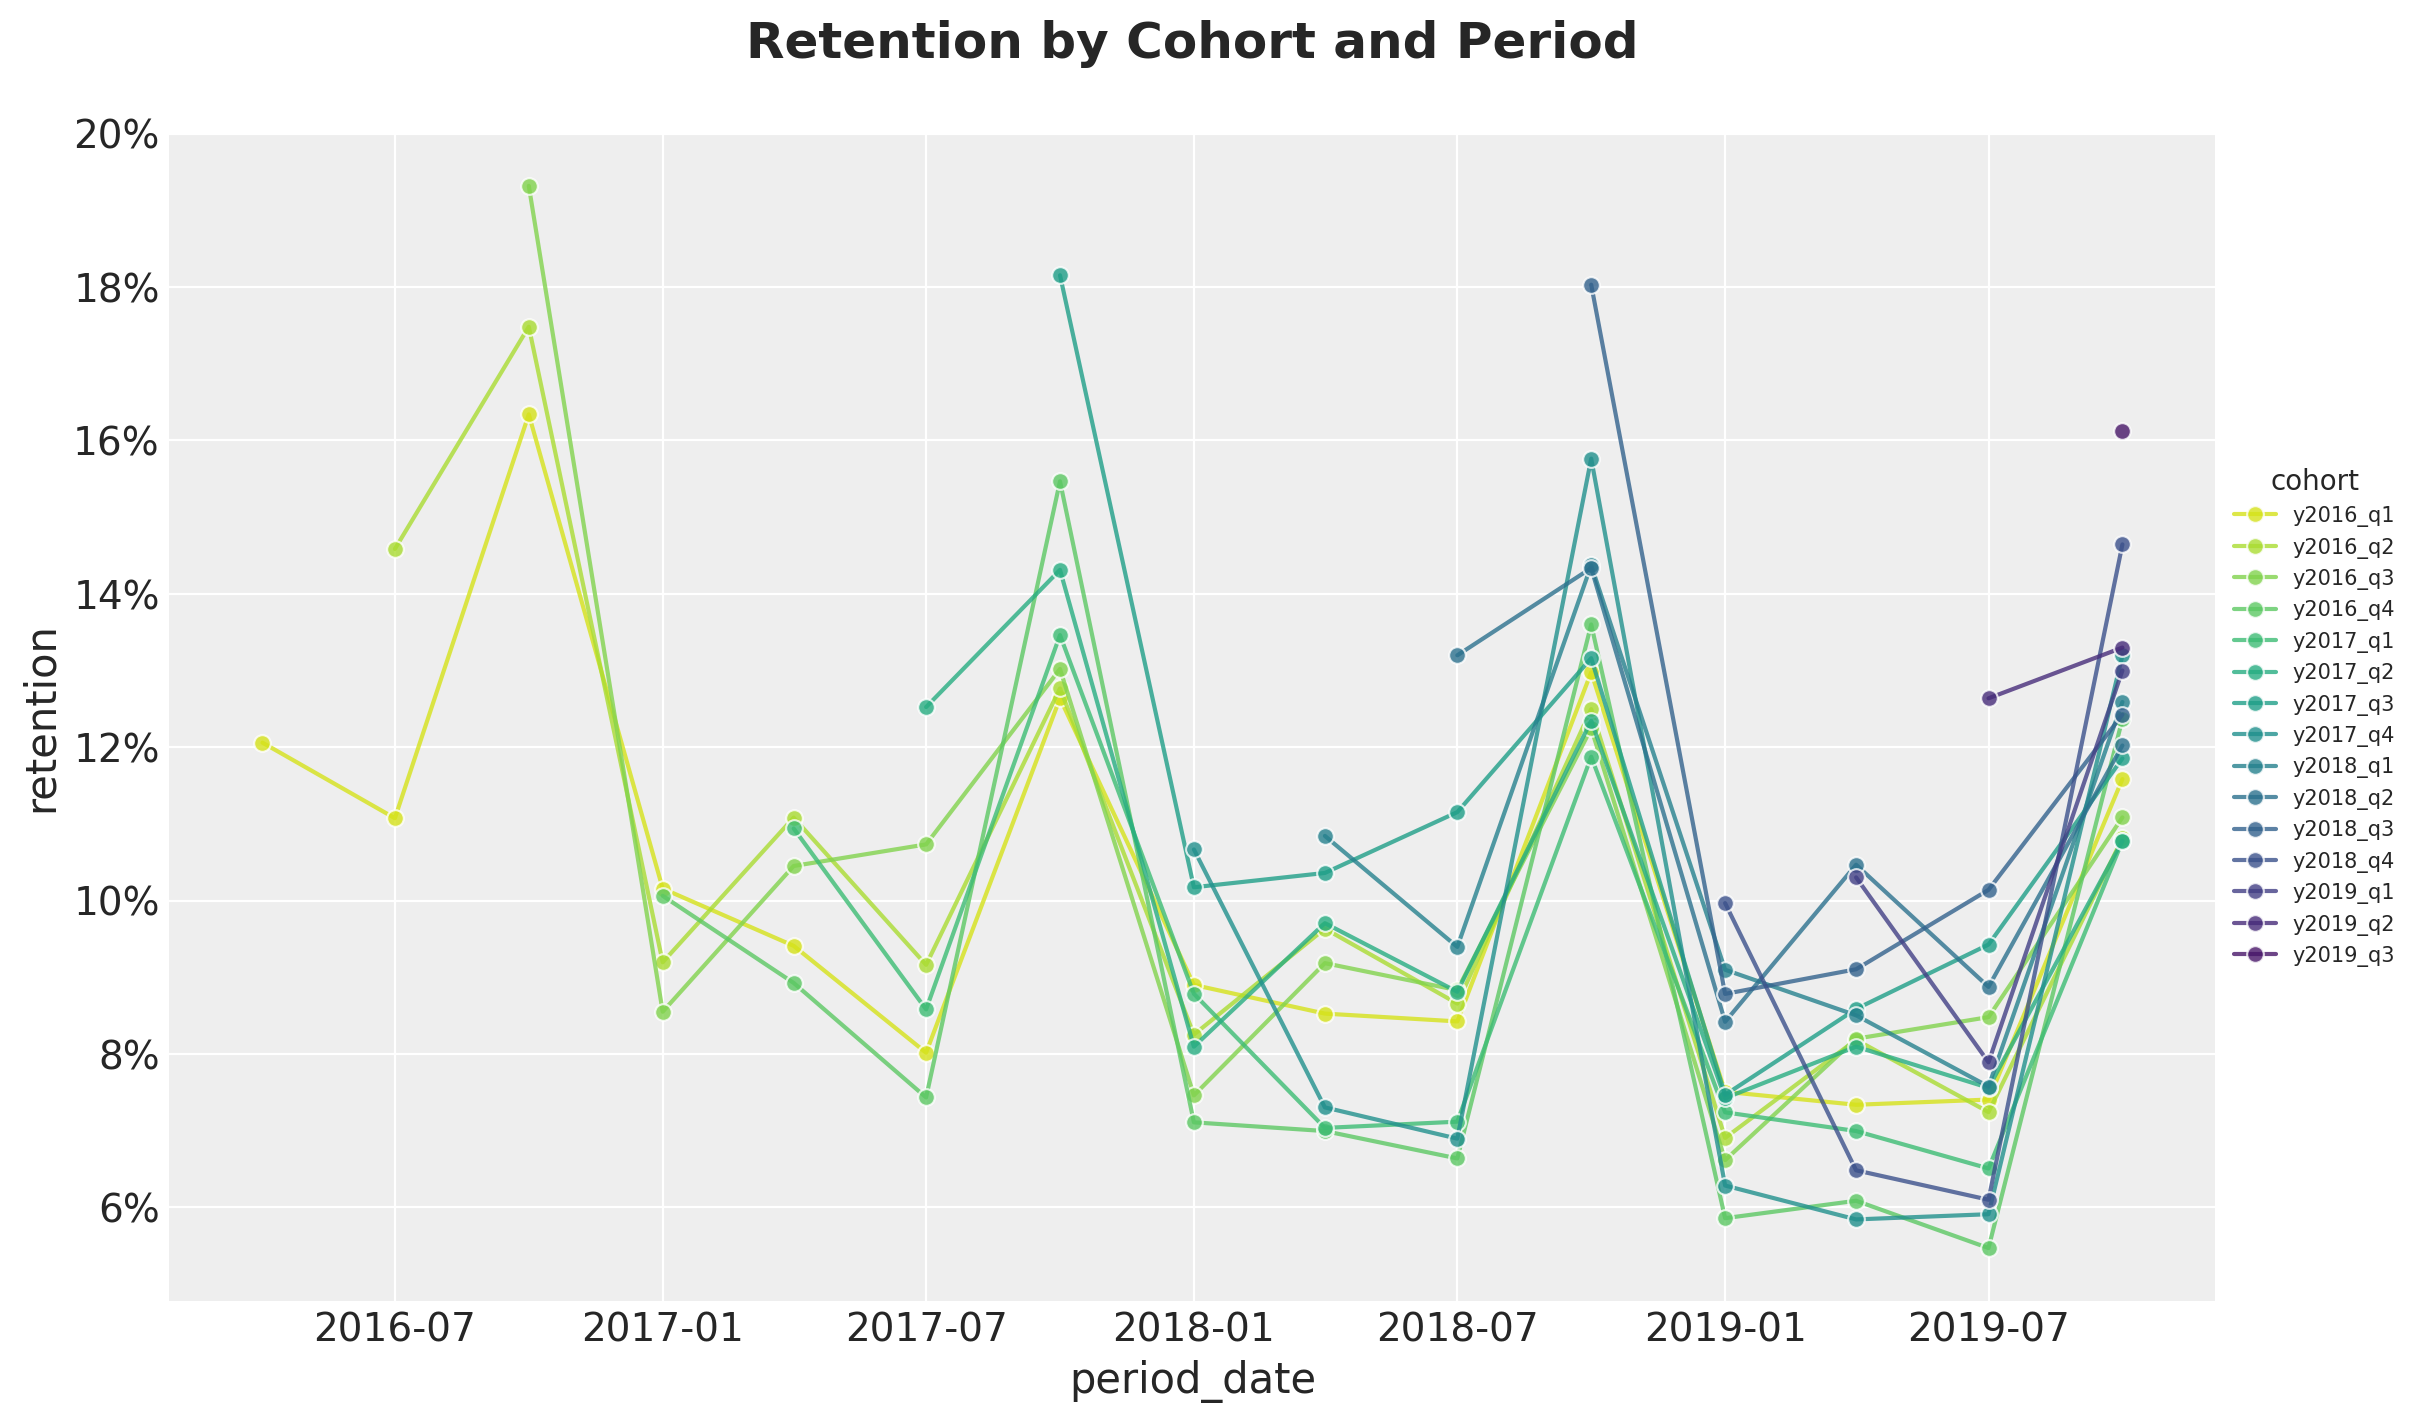

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.lineplot(
    x="period_date",
    y="retention",
    marker="o",
    hue="cohort",
    palette="viridis_r",
    alpha=0.8,
    data=data_df.query("cohort_age > 0"),
    ax=ax,
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.legend(title="cohort", loc="center left", bbox_to_anchor=(1, 0.5), fontsize=7.5)
ax.set_title("Retention by Cohort and Period", fontsize=18, fontweight="bold", y=1.05);

## Data Preparation

Now that we have a better feeling of the data, we can proceed to the data preparation for the model (similar as in the original code). To evaluate the model performance, we split the data into training and test sets. For the test set we use data from the period 2019-Q1 onwards so that we have one full year of data to evaluate the model.

In [12]:
period_train_test_split = "y2019-q1"

train_data_df = data_df.query(f"period <= '{period_train_test_split}'")
test_data_df = data_df.query(f"period > '{period_train_test_split}'")

In [13]:
eps = np.finfo(float).eps
train_data_red_df = train_data_df.query("cohort_age > 0").reset_index(drop=True)
train_obs_idx = train_data_red_df.index.to_numpy()
train_n_users = train_data_red_df["n_users"].to_numpy()
train_n_active_users = train_data_red_df["n_active_users"].to_numpy()
train_retention = train_data_red_df["retention"].to_numpy()
train_retention_logit = logit(train_retention + eps)
train_revenue = train_data_red_df["revenue"].to_numpy() + eps
train_revenue_per_user = train_revenue / (train_n_active_users + eps)

train_cohort = train_data_red_df["cohort"].to_numpy()
train_cohort_encoder = LabelEncoder()
train_cohort_idx = train_cohort_encoder.fit_transform(train_cohort).flatten()
train_period = train_data_red_df["period"].to_numpy()
train_period_encoder = LabelEncoder()
train_period_idx = train_period_encoder.fit_transform(train_period).flatten()

train_cohort_quarter = train_data_red_df["cohort_quarter"].to_numpy() - 1
train_period_quarter = train_data_red_df["period_quarter"].to_numpy() - 1

features: list[str] = ["age", "cohort_age", "cohort_quarter", "period_quarter"]
x_train = train_data_red_df[features]

train_age = train_data_red_df["age"].to_numpy()
train_age_scaler = MaxAbsScaler()
train_age_scaled = train_age_scaler.fit_transform(train_age.reshape(-1, 1)).flatten()
train_cohort_age = train_data_red_df["cohort_age"].to_numpy()
train_cohort_age_scaler = MaxAbsScaler()
train_cohort_age_scaled = train_cohort_age_scaler.fit_transform(
    train_cohort_age.reshape(-1, 1)
).flatten()

## Model Specification

Motivated by the analysis above we suggest the following retention-revenue model.

\begin{align*}
\text{Revenue} & \sim \text{Gamma}(N_{\text{active}}, \lambda) \\
\lambda & = \text{softplus}(\widetilde{\lambda}) \gt 0 \\
\widetilde{\lambda} = (& \text{intercept} \\
    & + \beta_{\text{cohort\_age}} \text{cohort age} \\
    & + \beta_{\text{age}} \text{age} \\
    & + \beta_{\text{cohort\_age} \times \text{age}} \text{cohort\_age} \times \text{age} \\ 
    & + \beta_{\text{cohort\_quarter}} \times \text{cohort\_quarter} \\
    & + \beta_{\text{period\_quarter}} \times \text{period\_quarter} ) \\
N_{\text{active}} & \sim \text{Binomial}(N_{\text{total}}, p) \\
\textrm{logit}(p) & = \text{BART}(\text{cohort\_age}, \text{age}, \text{cohort\_quarter}, \text{period\_quarter})
\end{align*}

Observe that, in contrast to the model in the pre-print, here we cohort and period seasonal effects in the revenue component explicitly (also, we use a softplus as a link function for the revenue component as it is numerically more stable).

Let's look into the PyMC model implementation.

/Users/juanitorduz/Documents/envs/pymc-marketing-env/lib/python3.12/site-packages/pymc_bart/bart.py:141: UserWarning: Options linear and mix are experimental and still not well tested
Use with caution.
  warnings.warn(


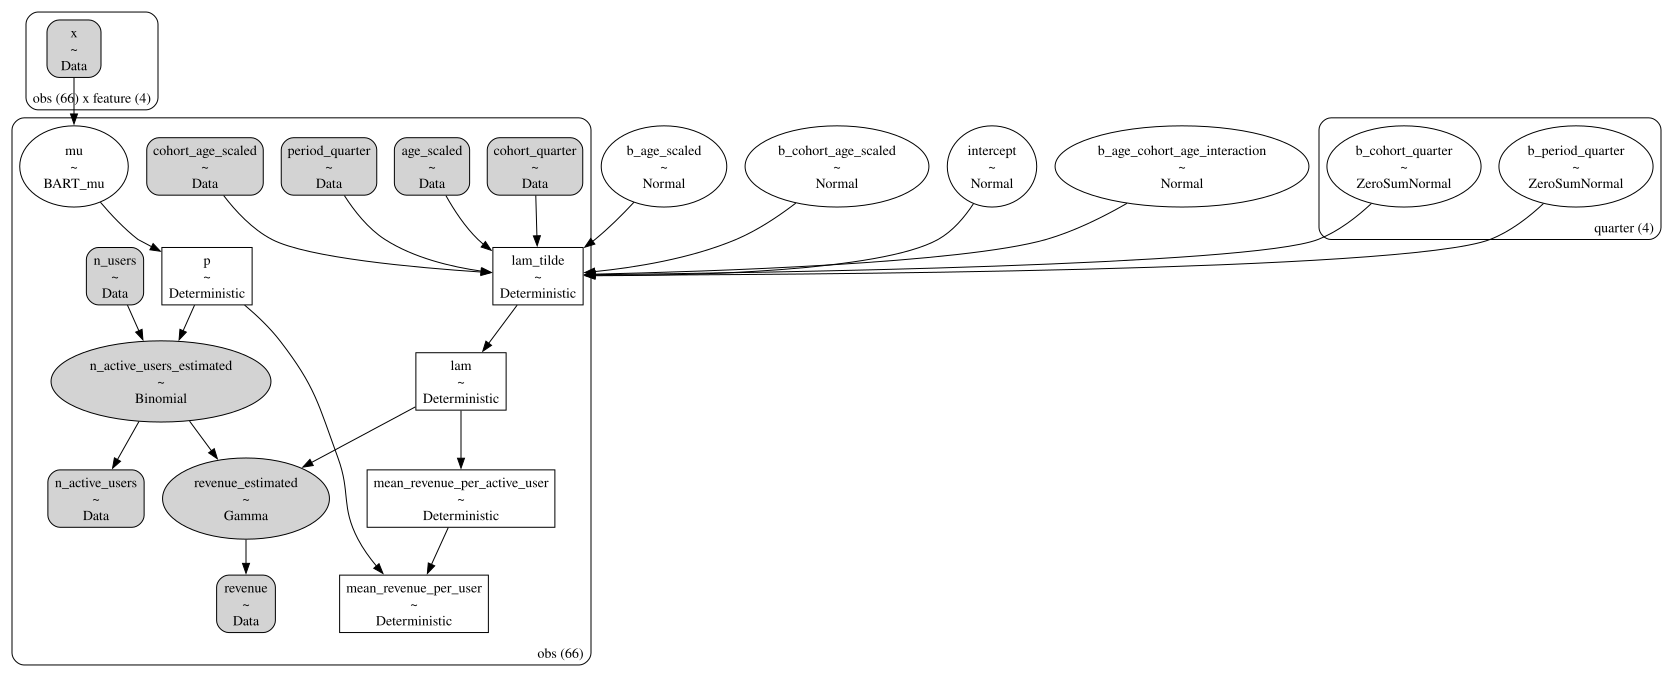

In [14]:
with pm.Model(coords={"feature": features, "quarter": range(4)}) as model:
    # --- Data ---
    model.add_coord(name="obs", values=train_obs_idx)
    age_scaled = pm.Data(name="age_scaled", value=train_age_scaled, dims="obs")
    cohort_age_scaled = pm.Data(
        name="cohort_age_scaled", value=train_cohort_age_scaled, dims="obs"
    )
    cohort_quarter = pm.Data(
        name="cohort_quarter", value=train_cohort_quarter, dims="obs"
    )
    period_quarter = pm.Data(
        name="period_quarter", value=train_period_quarter, dims="obs"
    )
    x = pm.Data(name="x", value=x_train, dims=("obs", "feature"))
    n_users = pm.Data(name="n_users", value=train_n_users, dims="obs")
    n_active_users = pm.Data(
        name="n_active_users", value=train_n_active_users, dims="obs"
    )
    revenue = pm.Data(name="revenue", value=train_revenue, dims="obs")

    # --- Priors ---
    intercept = pm.Normal(name="intercept", mu=0, sigma=2)
    b_age_scaled = pm.Normal(name="b_age_scaled", mu=0, sigma=1)
    b_cohort_age_scaled = pm.Normal(name="b_cohort_age_scaled", mu=0, sigma=1)
    b_age_cohort_age_interaction = pm.Normal(
        name="b_age_cohort_age_interaction", mu=0, sigma=1
    )
    # We use a zero-sum prior for the cohort and period seasonal effects so that
    # the sum of the effects is zero. We are mainly interested in the relative
    # differences.
    b_cohort_quarter = pm.ZeroSumNormal(
        name="b_cohort_quarter", sigma=1, dims="quarter"
    )
    b_period_quarter = pm.ZeroSumNormal(
        name="b_period_quarter", sigma=1, dims="quarter"
    )

    # --- Parametrization ---
    # The BART component models the image of the retention rate under the
    # logit transform so that the range is not constrained to [0, 1].
    mu = pmb.BART(
        name="mu",
        X=x,
        Y=train_retention_logit,
        m=200,
        response="mix",
        split_rules=[
            ContinuousSplitRule(),
            ContinuousSplitRule(),
            SubsetSplitRule(),
            SubsetSplitRule(),
        ],
        dims="obs",
    )
    # We use the inverse logit transform to get the retention rate back into [0, 1].
    p = pm.Deterministic(name="p", var=pm.math.invlogit(mu), dims="obs")
    # We add a small epsilon to avoid numerical issues.
    p = pt.switch(pt.eq(p, 0), eps, p)
    p = pt.switch(pt.eq(p, 1), 1 - eps, p)

    # For the revenue component we use a Gamma distribution where we combine the number
    # of estimated active users with the average revenue per user.
    lam_tilde = pm.Deterministic(
        name="lam_tilde",
        var=intercept
        + b_age_scaled * age_scaled
        + b_cohort_age_scaled * cohort_age_scaled
        + b_age_cohort_age_interaction * age_scaled * cohort_age_scaled
        # We add an additional seasonal effect for the cohorts
        + b_cohort_quarter[cohort_quarter]
        # We add an additional seasonal effect for the periods
        + b_period_quarter[period_quarter],
        dims="obs",
    )

    lam = pm.Deterministic(name="lam", var=pt.softplus(lam_tilde), dims="obs")

    # --- Likelihood ---
    n_active_users_estimated = pm.Binomial(
        name="n_active_users_estimated",
        n=n_users,
        p=p,
        observed=n_active_users,
        dims="obs",
    )

    x = pm.Gamma(
        name="revenue_estimated",
        alpha=n_active_users_estimated + eps,
        beta=lam,
        observed=revenue,
        dims="obs",
    )

    mean_revenue_per_active_user = pm.Deterministic(
        name="mean_revenue_per_active_user", var=(1 / lam), dims="obs"
    )
    pm.Deterministic(
        name="mean_revenue_per_user", var=p * mean_revenue_per_active_user, dims="obs"
    )

pm.model_to_graphviz(model=model)

## Model Fitting

We now fir the model.

In [15]:
with model:
    idata = pm.sample(draws=2_000, chains=4, random_seed=rng)
    idata.extend(pm.sample_posterior_predictive(trace=idata, random_seed=rng))

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>NUTS: [intercept, b_age_scaled, b_cohort_age_scaled, b_age_cohort_age_interaction, b_cohort_quarter, b_period_quarter]
>PGBART: [mu]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 118 seconds.
Sampling: [n_active_users_estimated, revenue_estimated]


Output()

## Model Diagnostics

Next, we inspect the model diagnostics.

In [16]:
# We do not have any divergent transitions.
assert idata.sample_stats["diverging"].sum().item() == 0

Let's look at the posterior predictive distribution against the observed data ( as a cumulative distribution).


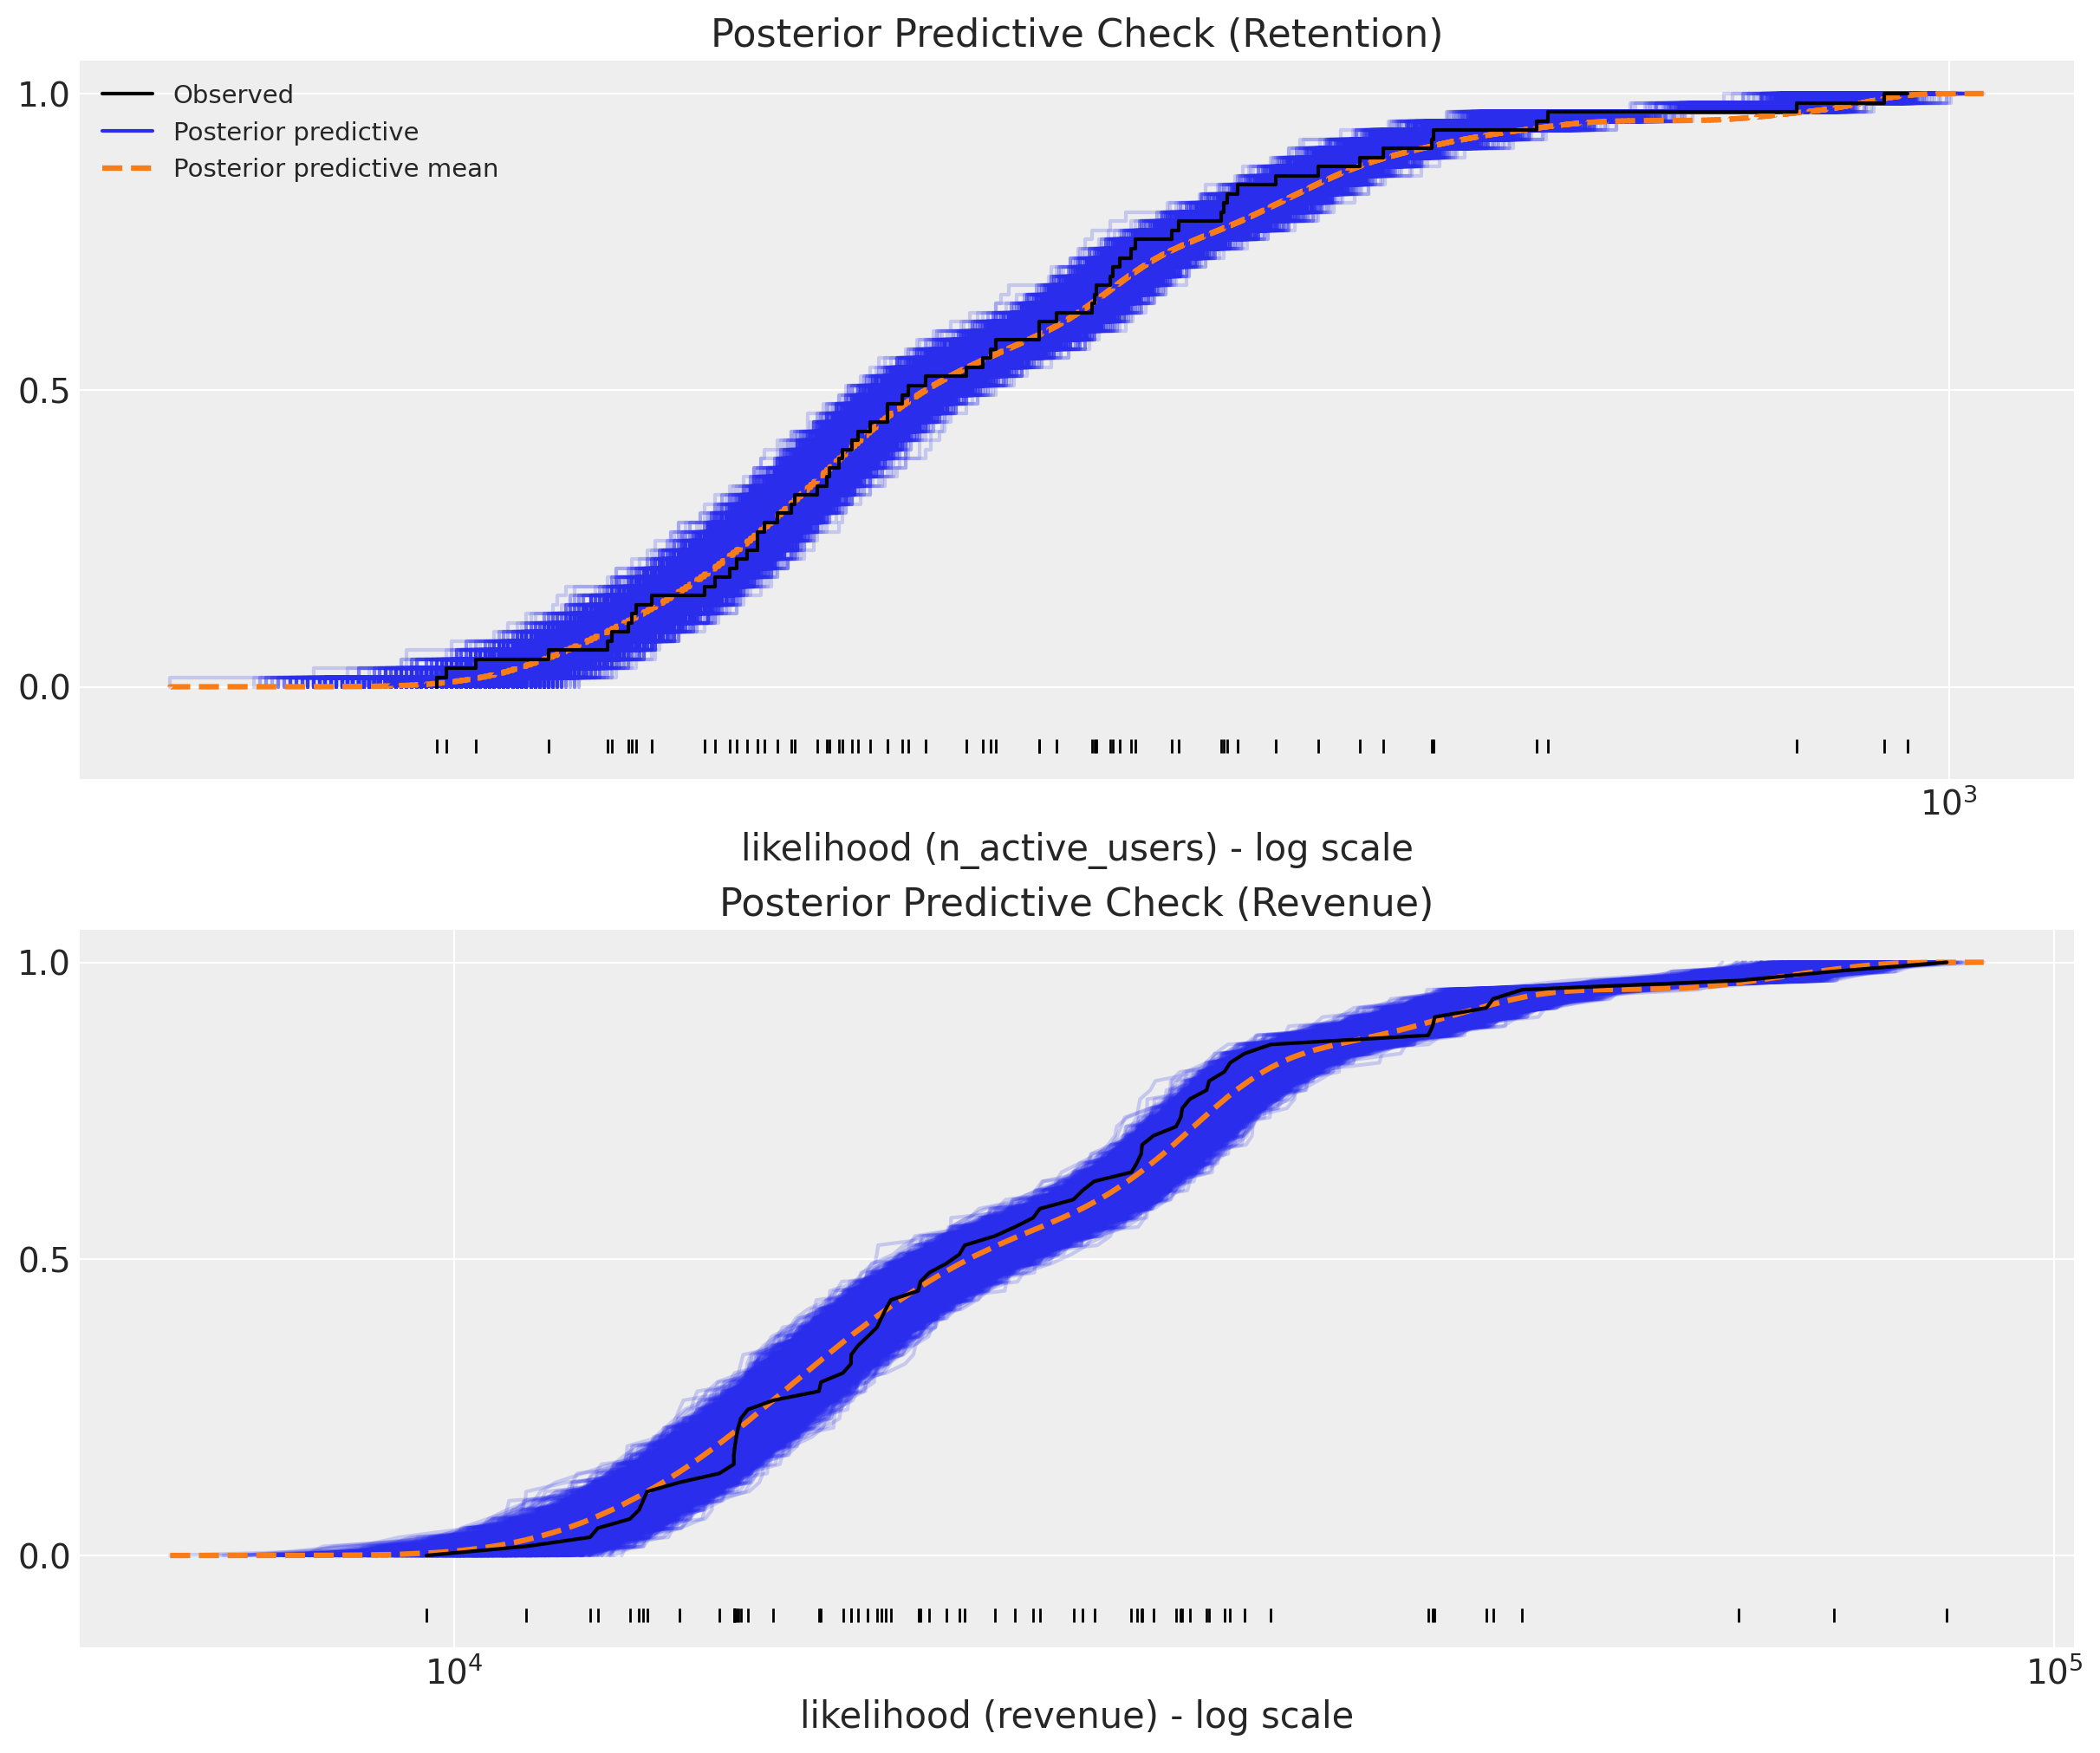

In [17]:
ax = az.plot_ppc(
    data=idata,
    kind="cumulative",
    observed_rug=True,
    grid=(2, 1),
    figsize=(12, 10),
    random_seed=seed,
)
ax[0].set(
    title="Posterior Predictive Check (Retention)",
    xscale="log",
    xlabel="likelihood (n_active_users) - log scale",
)
ax[1].set(
    title="Posterior Predictive Check (Revenue)",
    xscale="log",
    xlabel="likelihood (revenue) - log scale",
);

Overall, the model seems to fit the data well.

We can now look into the individual model components.

In [18]:
az.summary(
    idata,
    var_names=[
        "intercept",
        "b_age_scaled",
        "b_cohort_age_scaled",
        "b_age_cohort_age_interaction",
        "b_cohort_quarter",
        "b_period_quarter",
    ],
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-4.068,0.035,-4.135,-4.004,0.001,0.000,4698.0,5418.0,1.0
b_age_scaled,-0.208,0.057,-0.315,-0.100,0.001,0.001,4182.0,4532.0,1.0
b_cohort_age_scaled,-0.023,0.079,-0.166,0.130,0.001,0.001,4140.0,4519.0,1.0
b_age_cohort_age_interaction,-0.073,0.180,-0.407,0.272,0.003,0.002,4513.0,5179.0,1.0
b_cohort_quarter[0],-0.005,0.012,-0.028,0.016,0.000,0.000,9221.0,5589.0,1.0
b_cohort_quarter[1],-0.002,0.012,-0.025,0.019,0.000,0.000,9302.0,5658.0,1.0
b_cohort_quarter[2],0.010,0.013,-0.013,0.034,0.000,0.000,9153.0,5356.0,1.0
b_cohort_quarter[3],-0.002,0.011,-0.024,0.018,0.000,0.000,9730.0,6109.0,1.0
b_period_quarter[0],-0.023,0.014,-0.049,0.004,0.000,0.000,7737.0,5599.0,1.0
b_period_quarter[1],0.091,0.013,0.068,0.116,0.000,0.000,8074.0,5042.0,1.0


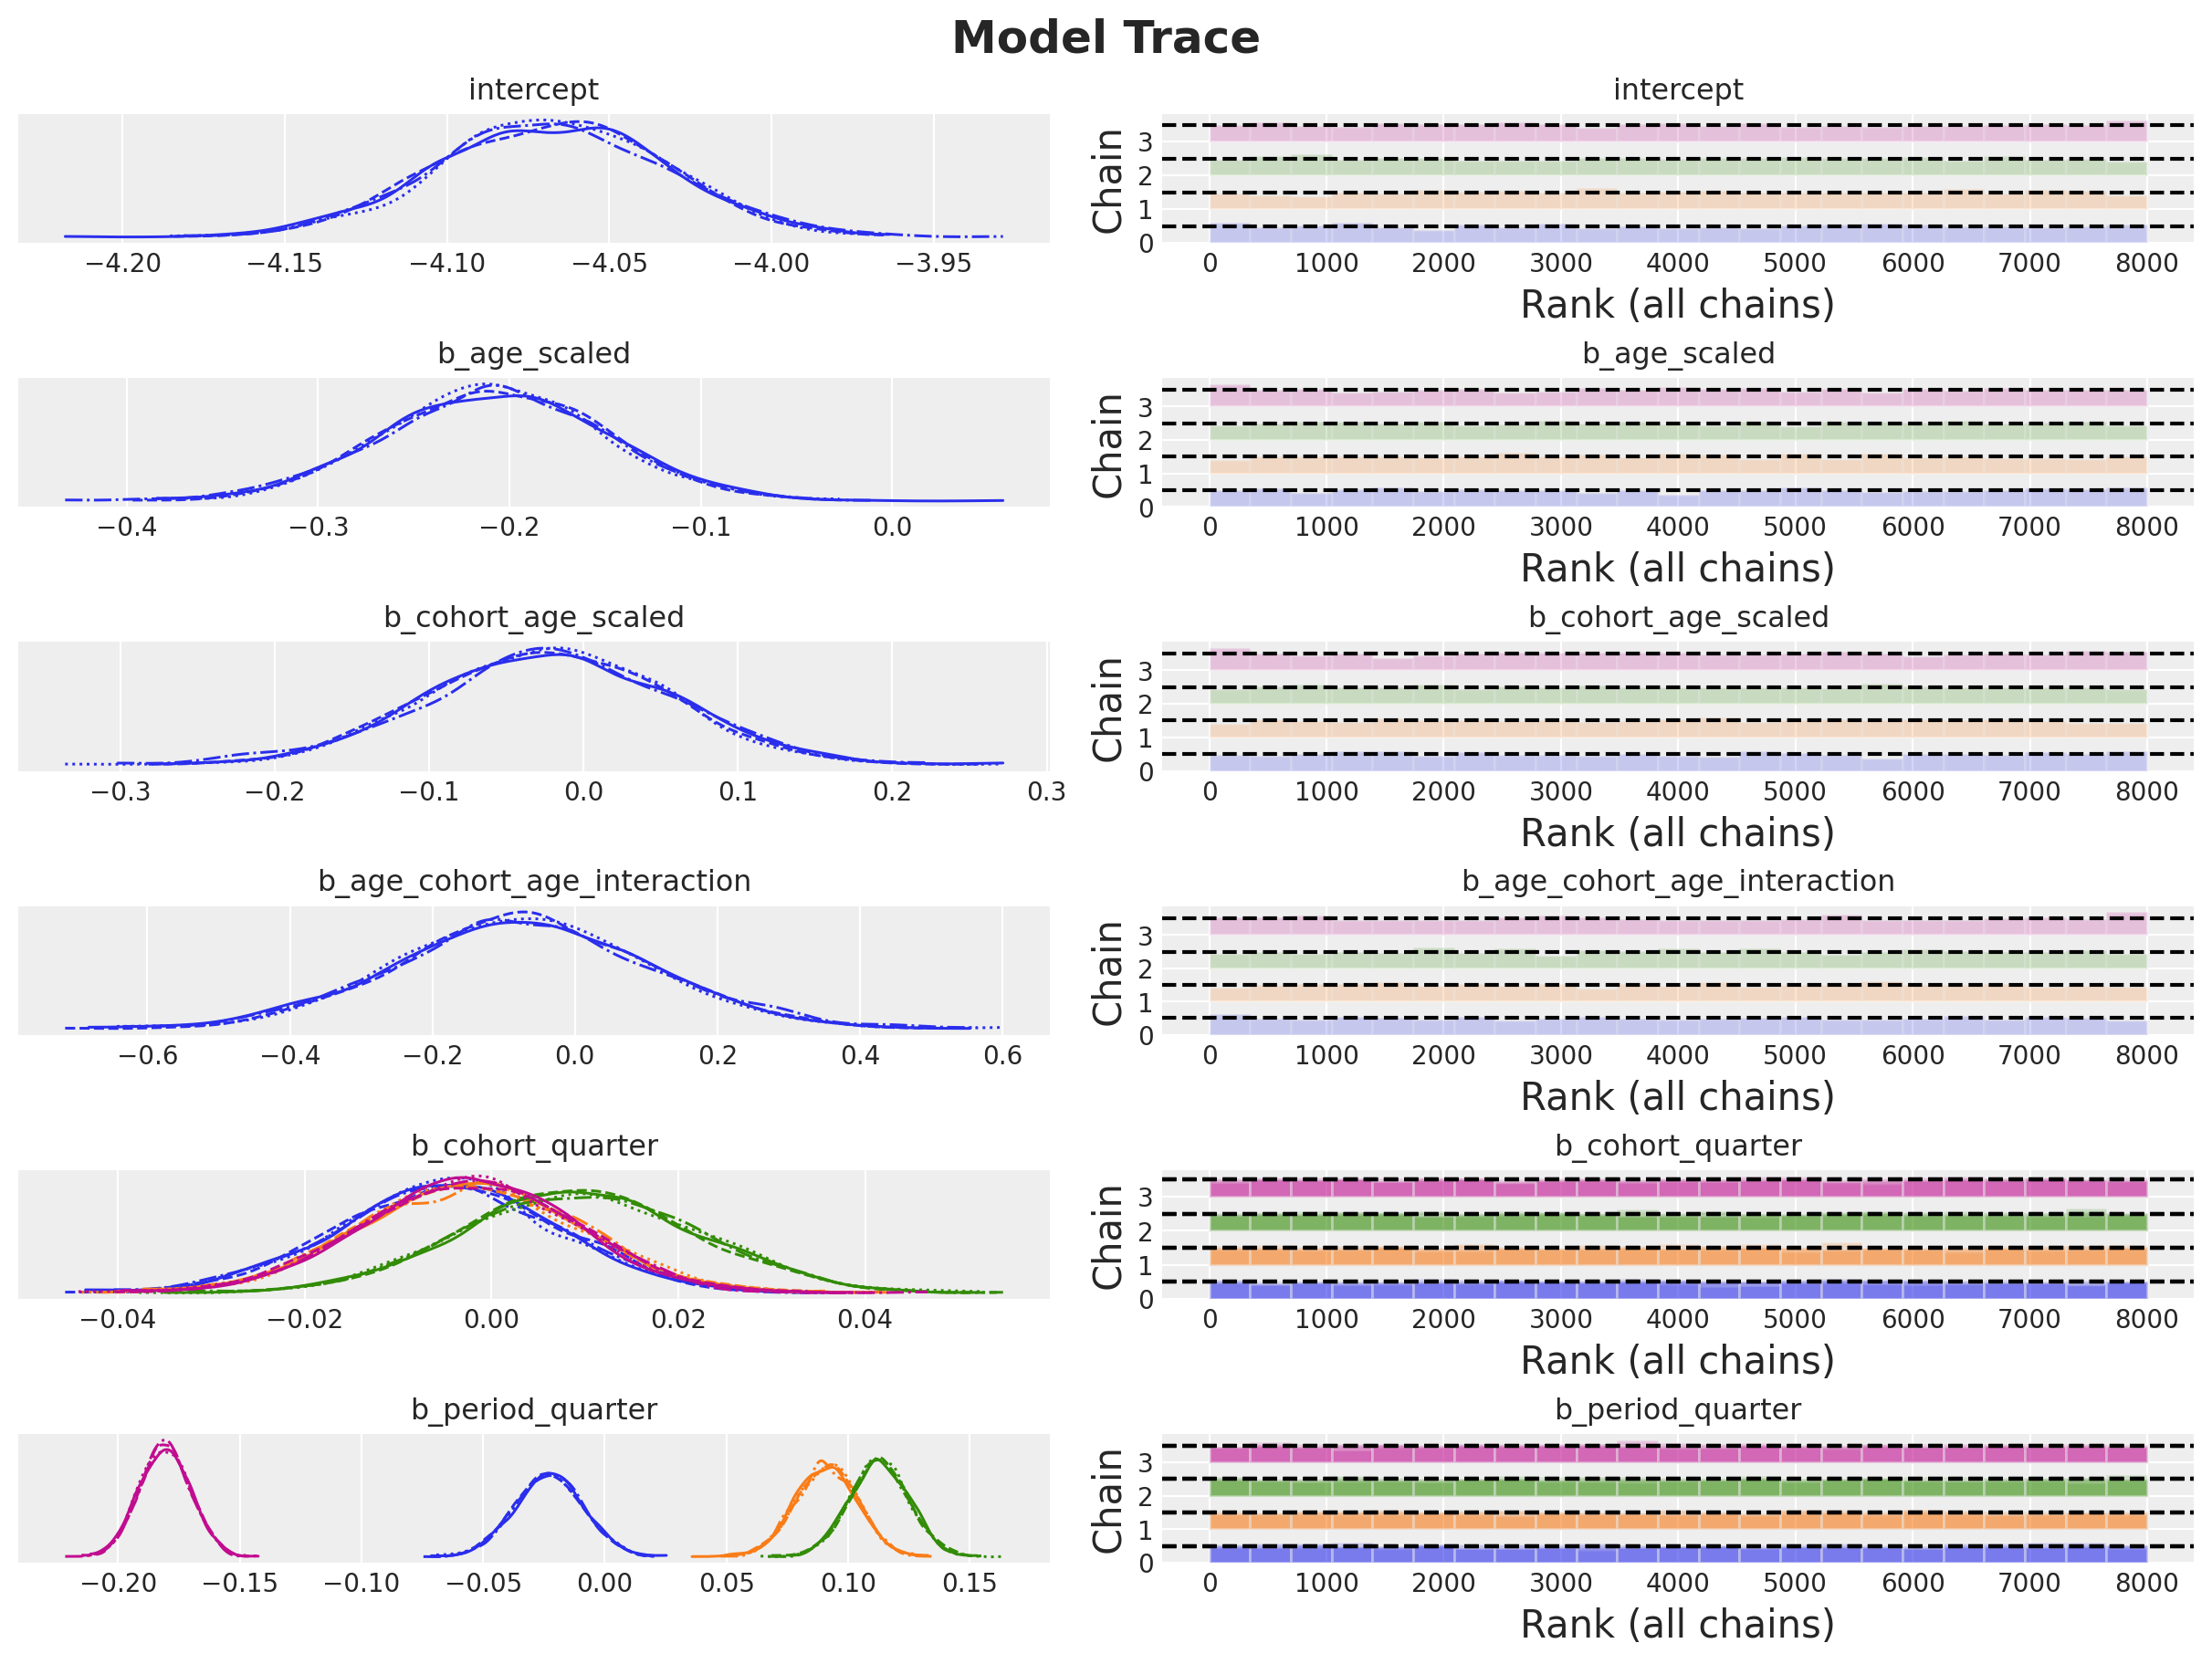

In [19]:
_ = az.plot_trace(
    data=idata,
    var_names=[
        "intercept",
        "b_age_scaled",
        "b_cohort_age_scaled",
        "b_age_cohort_age_interaction",
        "b_cohort_quarter",
        "b_period_quarter",
    ],
    compact=True,
    kind="rank_bars",
    backend_kwargs={"figsize": (12, 9), "layout": "constrained"},
)
plt.gcf().suptitle("Model Trace", fontsize=18, fontweight="bold");

The traces and chains are mixing well.

We can now look at the partial dependency plots (PDPs) to get a better understanding of how the predictions are made for the retention component (BART model).

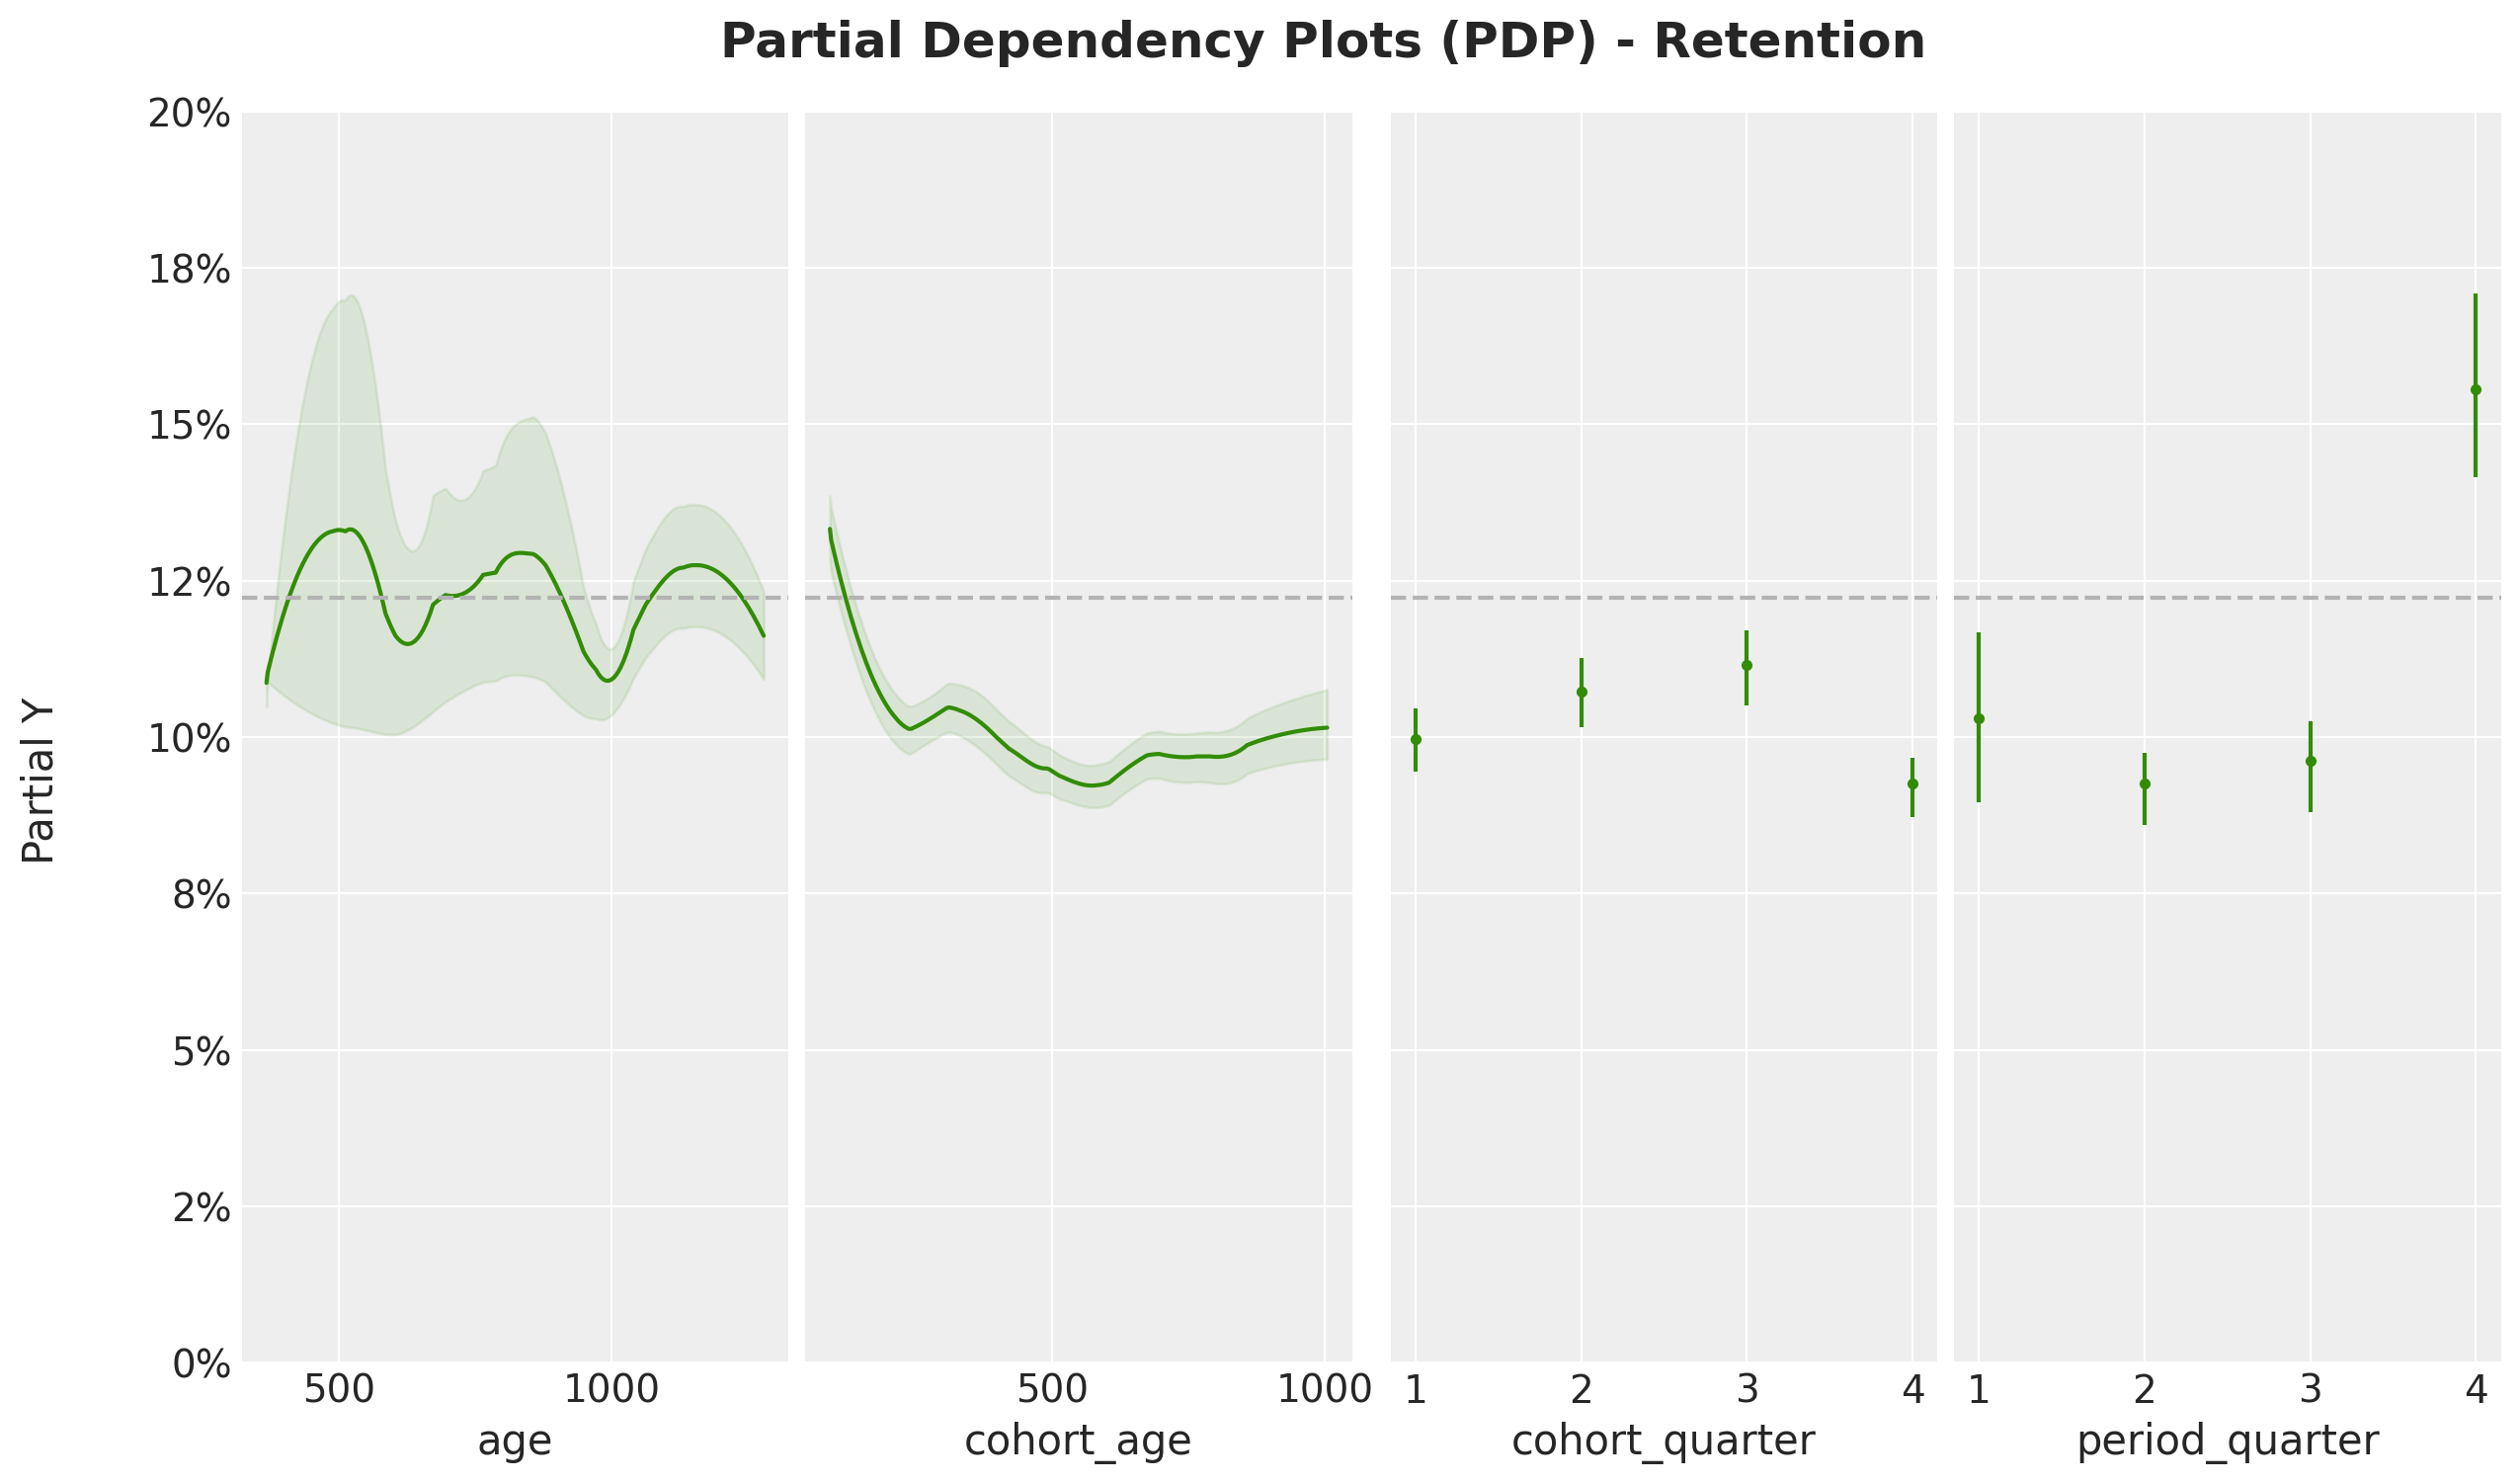

In [20]:
axes = pmb.plot_pdp(
    bartrv=mu,
    X=x_train,
    Y=train_retention,
    func=expit,
    xs_interval="insample",
    samples=1_000,
    grid="wide",
    color="C2",
    color_mean="C2",
    var_discrete=[2, 3],
    figsize=(12, 7),
    random_seed=seed,
)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[0].set(ylim=(0, 0.2))
plt.gcf().suptitle(
    "Partial Dependency Plots (PDP) - Retention",
    fontsize=18,
    fontweight="bold",
    y=1.05,
);

Here are some remarks on the PDPs:

- We see a clear and strong seasonal effect of the `period_quarter` variable.
- The `age` variable also shows a clear seasonal effect which comes also from the `cohort_period` as these variables are highly correlated.
- We see a decay in retention as a function of the `cohort_age` variable. This is interesting as we this decaying curve represent the retention decrease over time controlling by seasonality components.

## In-Sample Predictions

Let's now look at the in-sample predictions. We want to understand how the model is able to fit the data. We use the [CRPS](https://towardsdatascience.com/crps-a-scoring-function-for-bayesian-machine-learning-models-dd55a7a337a8/) as a scoring function to evaluate the model performance. This metric is a generalization of the mean absolute error to the case of probabilistic predictions.


In [21]:
train_posterior_retention = idata["posterior"]["p"]

train_posterior_retention_mean = az.extract(
    data=train_posterior_retention, var_names=["p"]
).mean("sample")

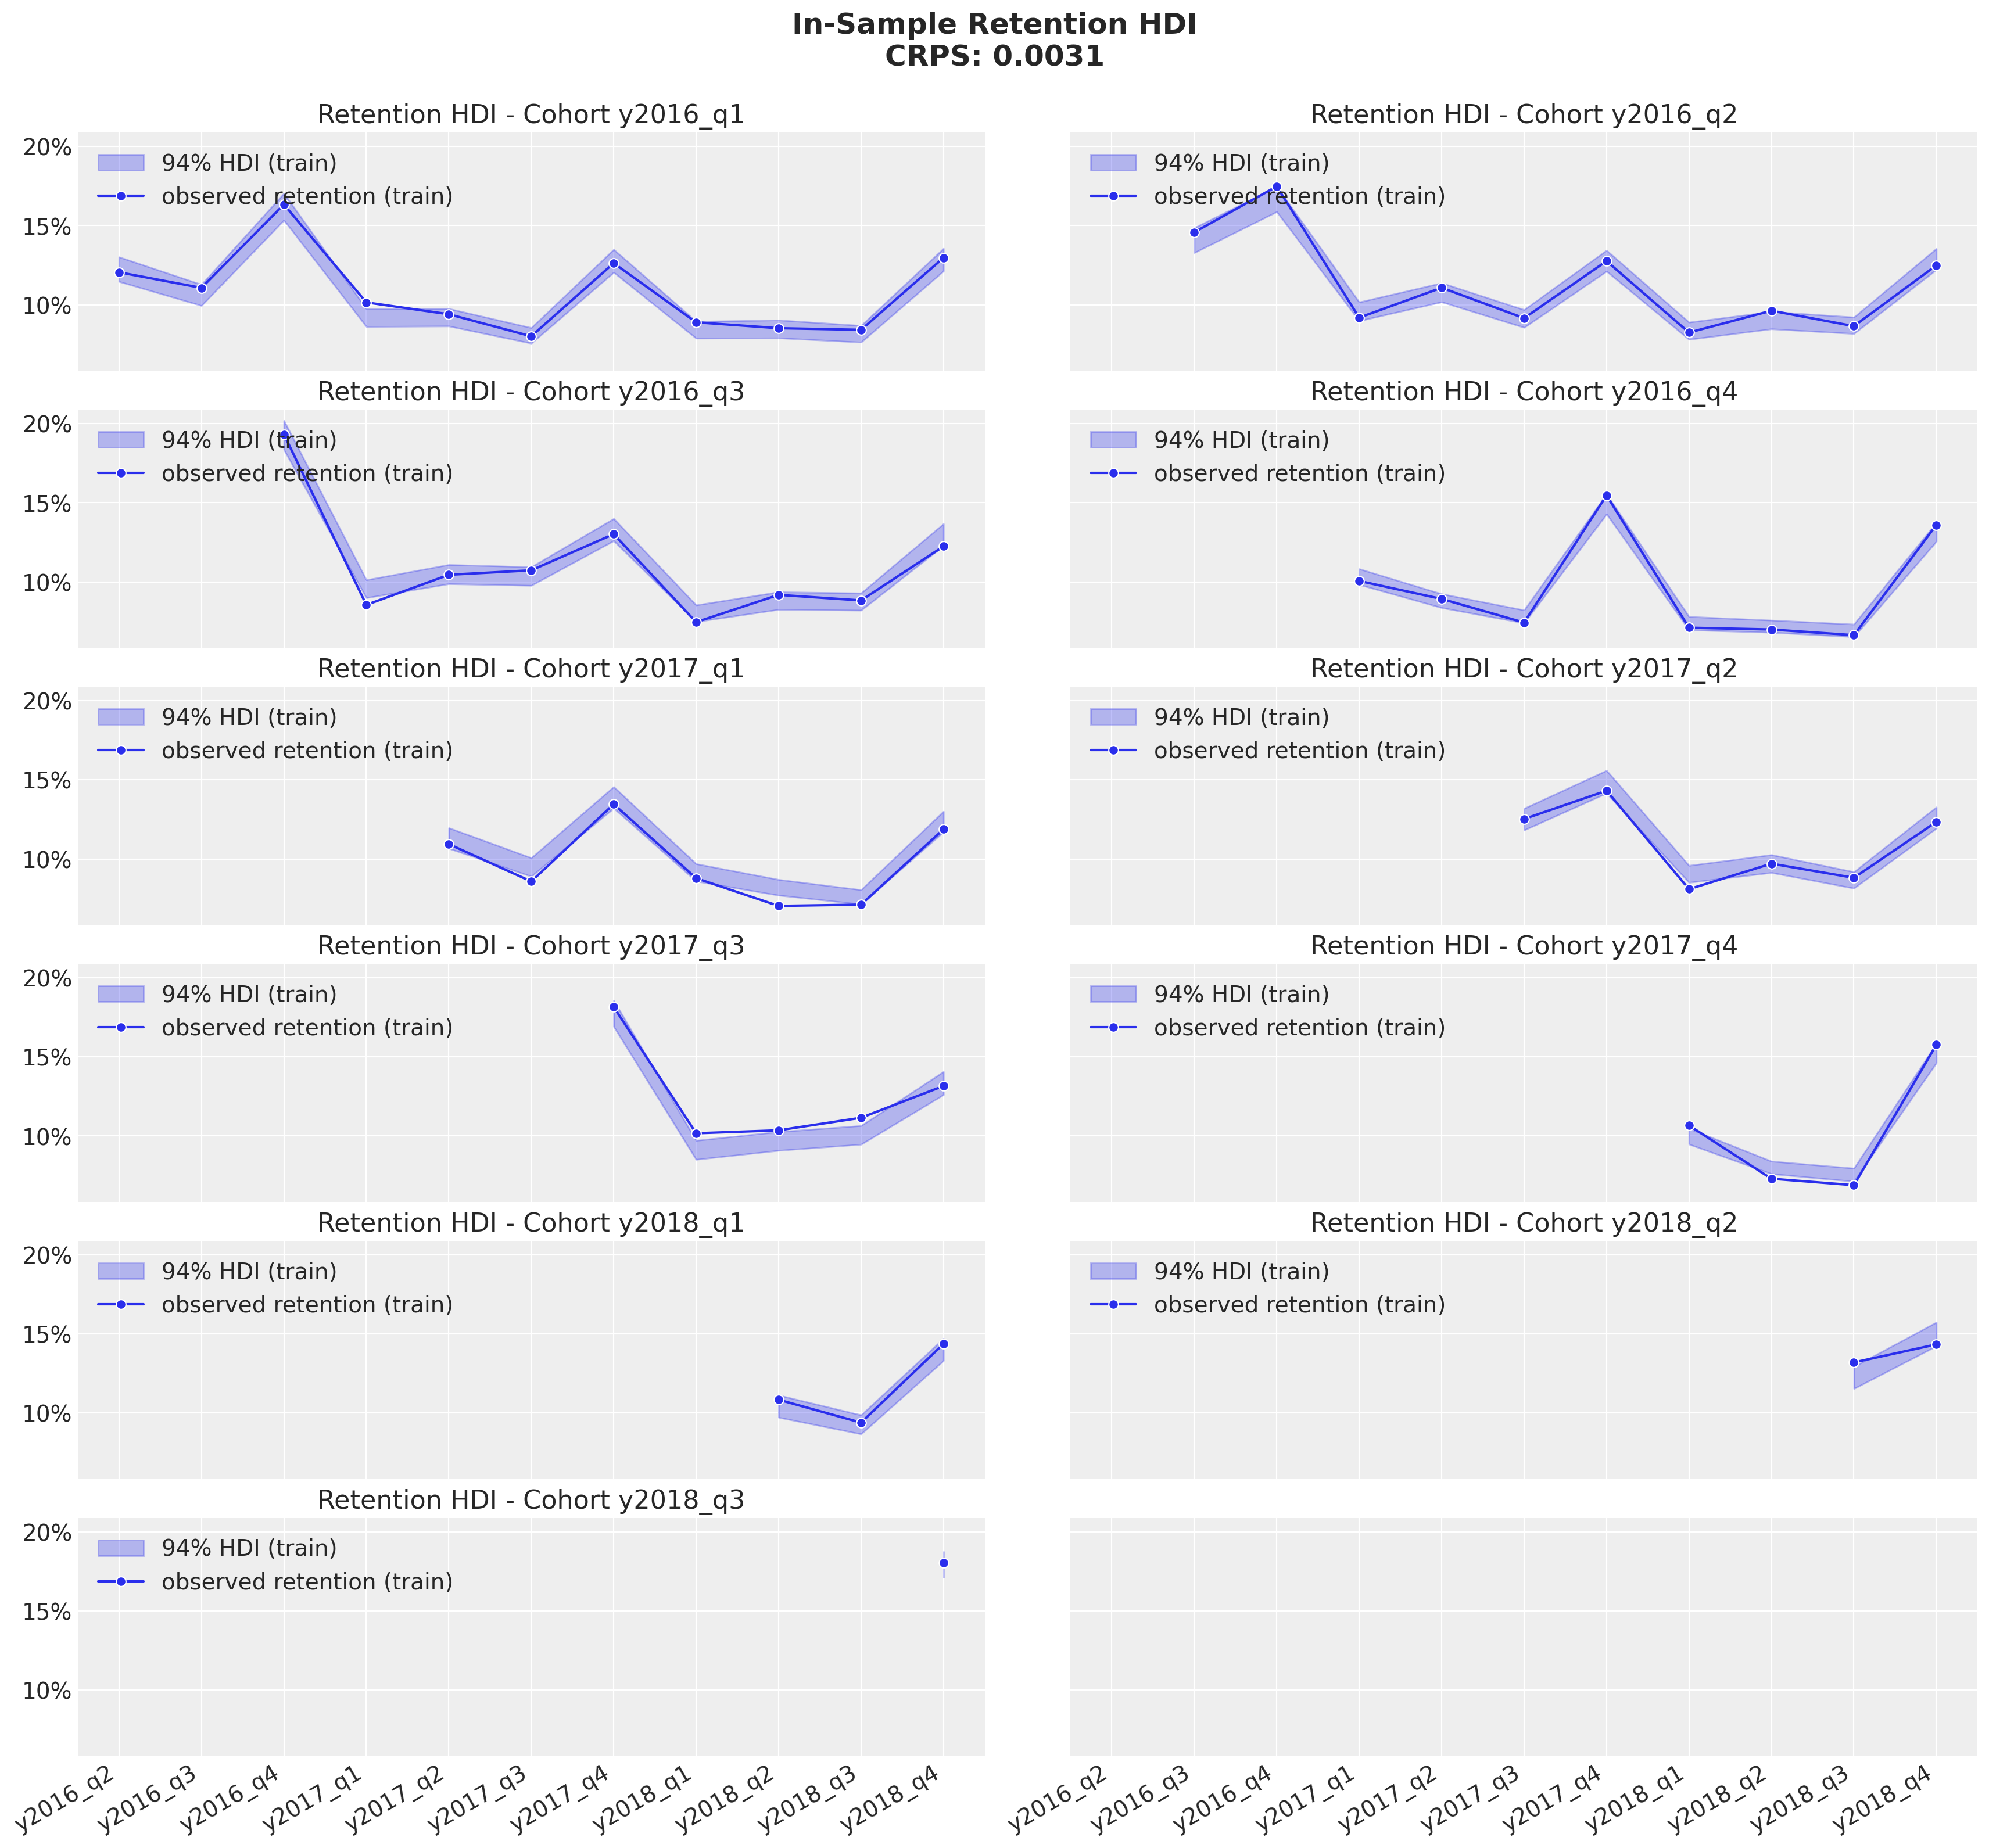

In [22]:
train_retention_hdi = az.hdi(ary=train_posterior_retention)["p"]


def plot_train_retention_hdi_cohort(cohort_index: int, ax: plt.Axes) -> plt.Axes:
    mask = train_cohort_idx == cohort_index

    ax.fill_between(
        x=train_period[train_period_idx[mask]],
        y1=train_retention_hdi[mask, :][:, 0],
        y2=train_retention_hdi[mask, :][:, 1],
        alpha=0.3,
        color="C0",
        label="94% HDI (train)",
    )
    sns.lineplot(
        x=train_period[train_period_idx[mask]],
        y=train_retention[mask],
        color="C0",
        marker="o",
        label="observed retention (train)",
        ax=ax,
    )
    cohort_name = train_cohort_encoder.classes_[cohort_index]
    ax.legend(loc="upper left")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set(title=f"Retention HDI - Cohort {cohort_name}")
    return ax


cohort_index_to_plot = range(train_data_df["cohort"].nunique() - 1)

fig, axes = plt.subplots(
    nrows=np.ceil(len(cohort_index_to_plot) / 2).astype(int),
    ncols=2,
    figsize=(17, 15),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for cohort_index, ax in zip(cohort_index_to_plot, axes.flatten(), strict=False):
    plot_train_retention_hdi_cohort(cohort_index=cohort_index, ax=ax)

in_sample_crps = crps(
    y_true=train_retention,
    y_pred=az.extract(data=train_posterior_retention, var_names=["p"]).T,
)

fig.suptitle(
    f"In-Sample Retention HDI\nCRPS:{in_sample_crps: .4f}",
    fontsize=18,
    fontweight="bold",
    y=1.05,
)
fig.autofmt_xdate()

We see that the model is able to fit the retention data quite well. It captures both the trend and seasonal effects.

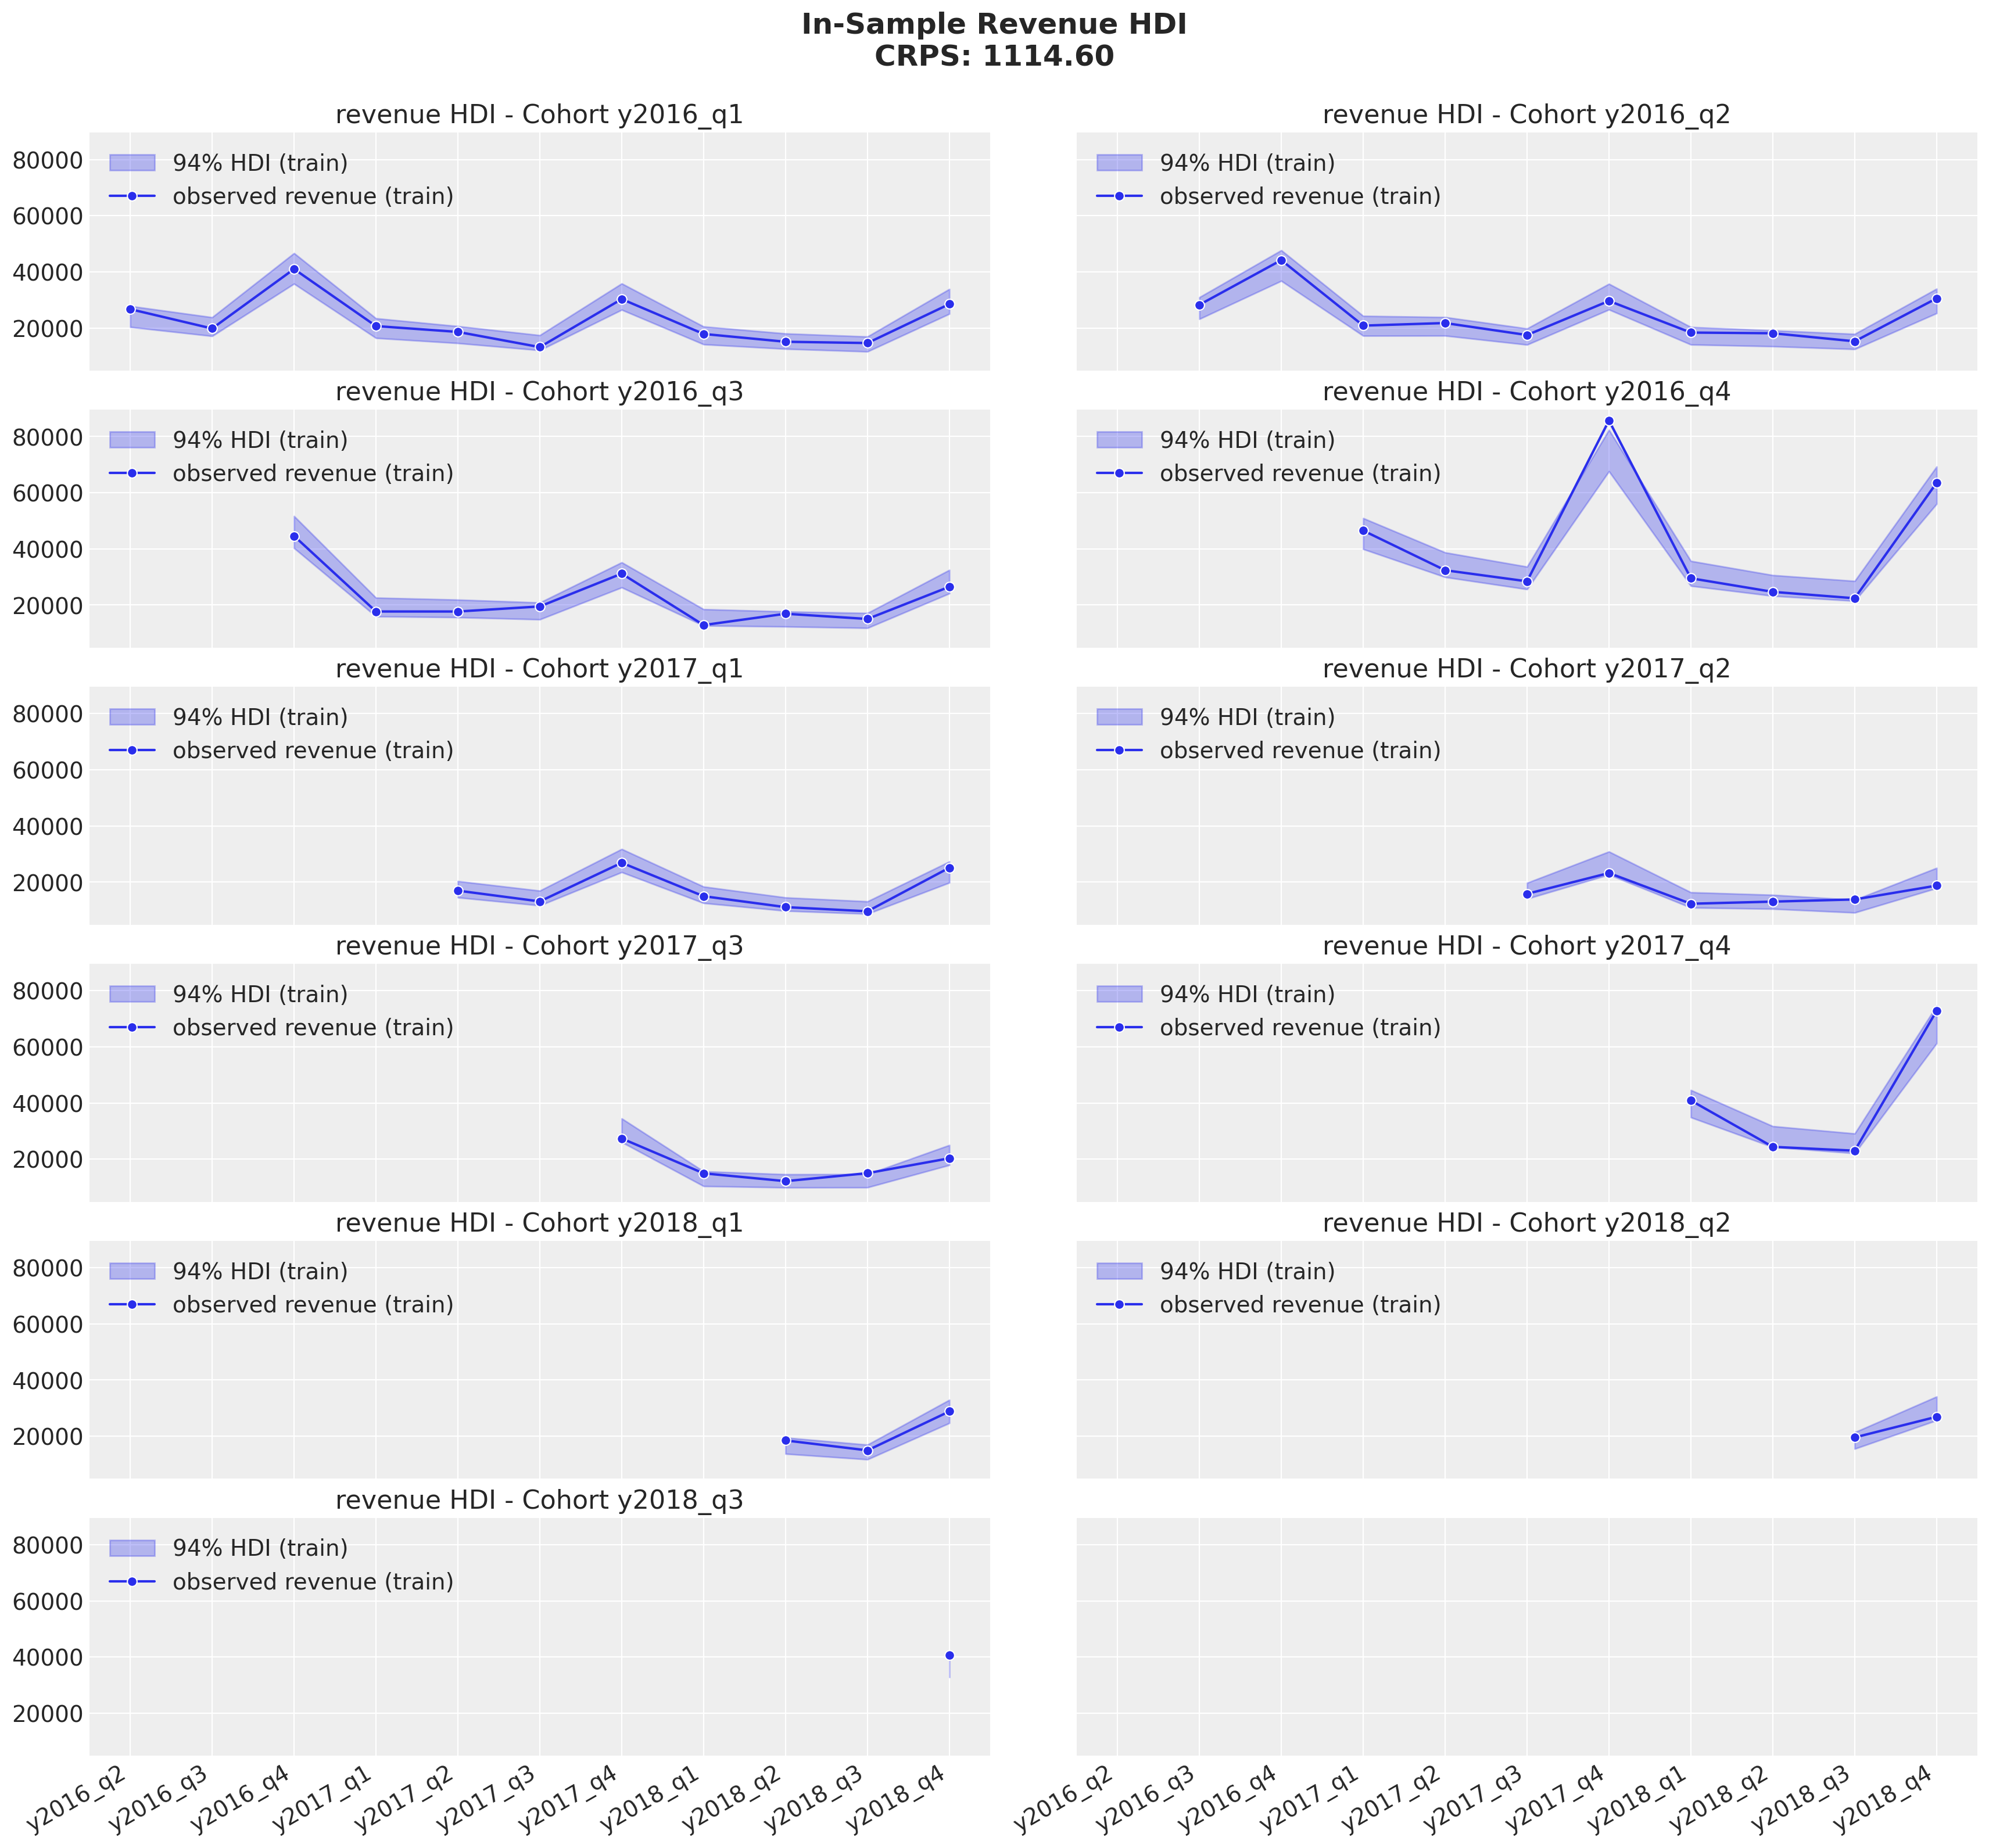

In [23]:
train_revenue_hdi = az.hdi(ary=idata.posterior_predictive)["revenue_estimated"]


def plot_train_revenue_hdi_cohort(cohort_index: int, ax: plt.Axes) -> plt.Axes:
    mask = train_cohort_idx == cohort_index

    ax.fill_between(
        x=train_period[train_period_idx[mask]],
        y1=train_revenue_hdi[mask, :][:, 0],
        y2=train_revenue_hdi[mask, :][:, 1],
        alpha=0.3,
        color="C0",
        label="94% HDI (train)",
    )
    sns.lineplot(
        x=train_period[train_period_idx[mask]],
        y=train_revenue[mask],
        color="C0",
        marker="o",
        label="observed revenue (train)",
        ax=ax,
    )
    cohort_name = train_cohort_encoder.classes_[cohort_index]
    ax.legend(loc="upper left")
    ax.set(title=f"revenue HDI - Cohort {cohort_name}")
    return ax


cohort_index_to_plot = range(train_data_df["cohort"].nunique() - 1)

fig, axes = plt.subplots(
    nrows=np.ceil(len(cohort_index_to_plot) / 2).astype(int),
    ncols=2,
    figsize=(17, 15),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for cohort_index, ax in zip(cohort_index_to_plot, axes.flatten(), strict=False):
    plot_train_revenue_hdi_cohort(cohort_index=cohort_index, ax=ax)

revenue_in_sample_crps = crps(
    y_true=train_revenue,
    y_pred=az.extract(
        data=idata.posterior_predictive, var_names=["revenue_estimated"]
    ).T,
)

fig.suptitle(
    f"In-Sample Revenue HDI\nCRPS:{revenue_in_sample_crps: .2f}",
    fontsize=18,
    fontweight="bold",
    y=1.05,
)
fig.autofmt_xdate();

The same holds for the revenue data.

## Out-of-Sample Predictions

Finally, we look at the out-of-sample predictions.

To generate the out-of-sample estimates, we need to pus the test data through the same preprocessing pipeline as the training data and then use the model to make predictions.


In [24]:
test_data_red_df = test_data_df.query("cohort_age > 0")
test_data_red_df = test_data_red_df[
    test_data_red_df["cohort"].isin(train_data_red_df["cohort"].unique())
].reset_index(drop=True)
test_obs_idx = test_data_red_df.index.to_numpy()
test_n_users = test_data_red_df["n_users"].to_numpy()
test_n_active_users = test_data_red_df["n_active_users"].to_numpy()
test_retention = test_data_red_df["retention"].to_numpy()
test_revenue = test_data_red_df["revenue"].to_numpy()

test_cohort = test_data_red_df["cohort"].to_numpy()
test_cohort_idx = train_cohort_encoder.transform(test_cohort).flatten()

test_cohort_quarter = test_data_red_df["cohort_quarter"].to_numpy() - 1
test_period_quarter = test_data_red_df["period_quarter"].to_numpy() - 1

x_test = test_data_red_df[features]

test_age = test_data_red_df["age"].to_numpy()
test_age_scaled = train_age_scaler.transform(test_age.reshape(-1, 1)).flatten()
test_cohort_age = test_data_red_df["cohort_age"].to_numpy()
test_cohort_age_scaled = train_cohort_age_scaler.transform(
    test_cohort_age.reshape(-1, 1)
).flatten()

In [25]:
with model:
    pm.set_data(
        new_data={
            "age_scaled": test_age_scaled,
            "cohort_age_scaled": test_cohort_age_scaled,
            "x": x_test,
            "n_users": test_n_users,
            "n_active_users": np.ones_like(
                test_n_active_users
            ),  # Dummy data to make coords work!
            # We are not using this at prediction time!
            "revenue": np.ones_like(test_revenue),  # Dummy data to make coords work!
            # We are not using this at prediction time!
            "cohort_quarter": test_cohort_quarter,
            "period_quarter": test_period_quarter,
        },
        coords={"obs": test_obs_idx},
    )
    posterior_predictive_test = pm.sample_posterior_predictive(
        trace=idata,
        var_names=[
            "p",
            "mu",
            "n_active_users_estimated",
            "revenue_estimated",
            "mean_revenue_per_user",
            "mean_revenue_per_active_user",
        ],
        idata_kwargs={"coords": {"obs": test_obs_idx}},
        random_seed=rng,
    )

Sampling: [mu, n_active_users_estimated, revenue_estimated]


Output()

We are now ready to make the out-of-sample predictions.

In [26]:
test_posterior_retention = (
    posterior_predictive_test.posterior_predictive["n_active_users_estimated"]
    / test_n_users[np.newaxis, None]
)

test_retention_hdi = az.hdi(ary=test_posterior_retention)["n_active_users_estimated"]
test_revenue_hdi = az.hdi(ary=posterior_predictive_test.posterior_predictive)[
    "revenue_estimated"
]

In [27]:
def plot_test_retention_hdi_cohort(cohort_index: int, ax: plt.Axes) -> plt.Axes:
    mask = test_cohort_idx == cohort_index

    test_period_range = test_data_red_df.query(
        f"cohort == '{train_cohort_encoder.classes_[cohort_index]}'"
    )["period"]

    ax.fill_between(
        x=test_period_range,
        y1=test_retention_hdi[mask, :][:, 0],
        y2=test_retention_hdi[mask, :][:, 1],
        alpha=0.3,
        color="C1",
        label="94% HDI (test)",
    )
    sns.lineplot(
        x=test_period_range,
        y=test_retention[mask],
        color="C1",
        marker="o",
        label="observed retention (test)",
        ax=ax,
    )
    return ax

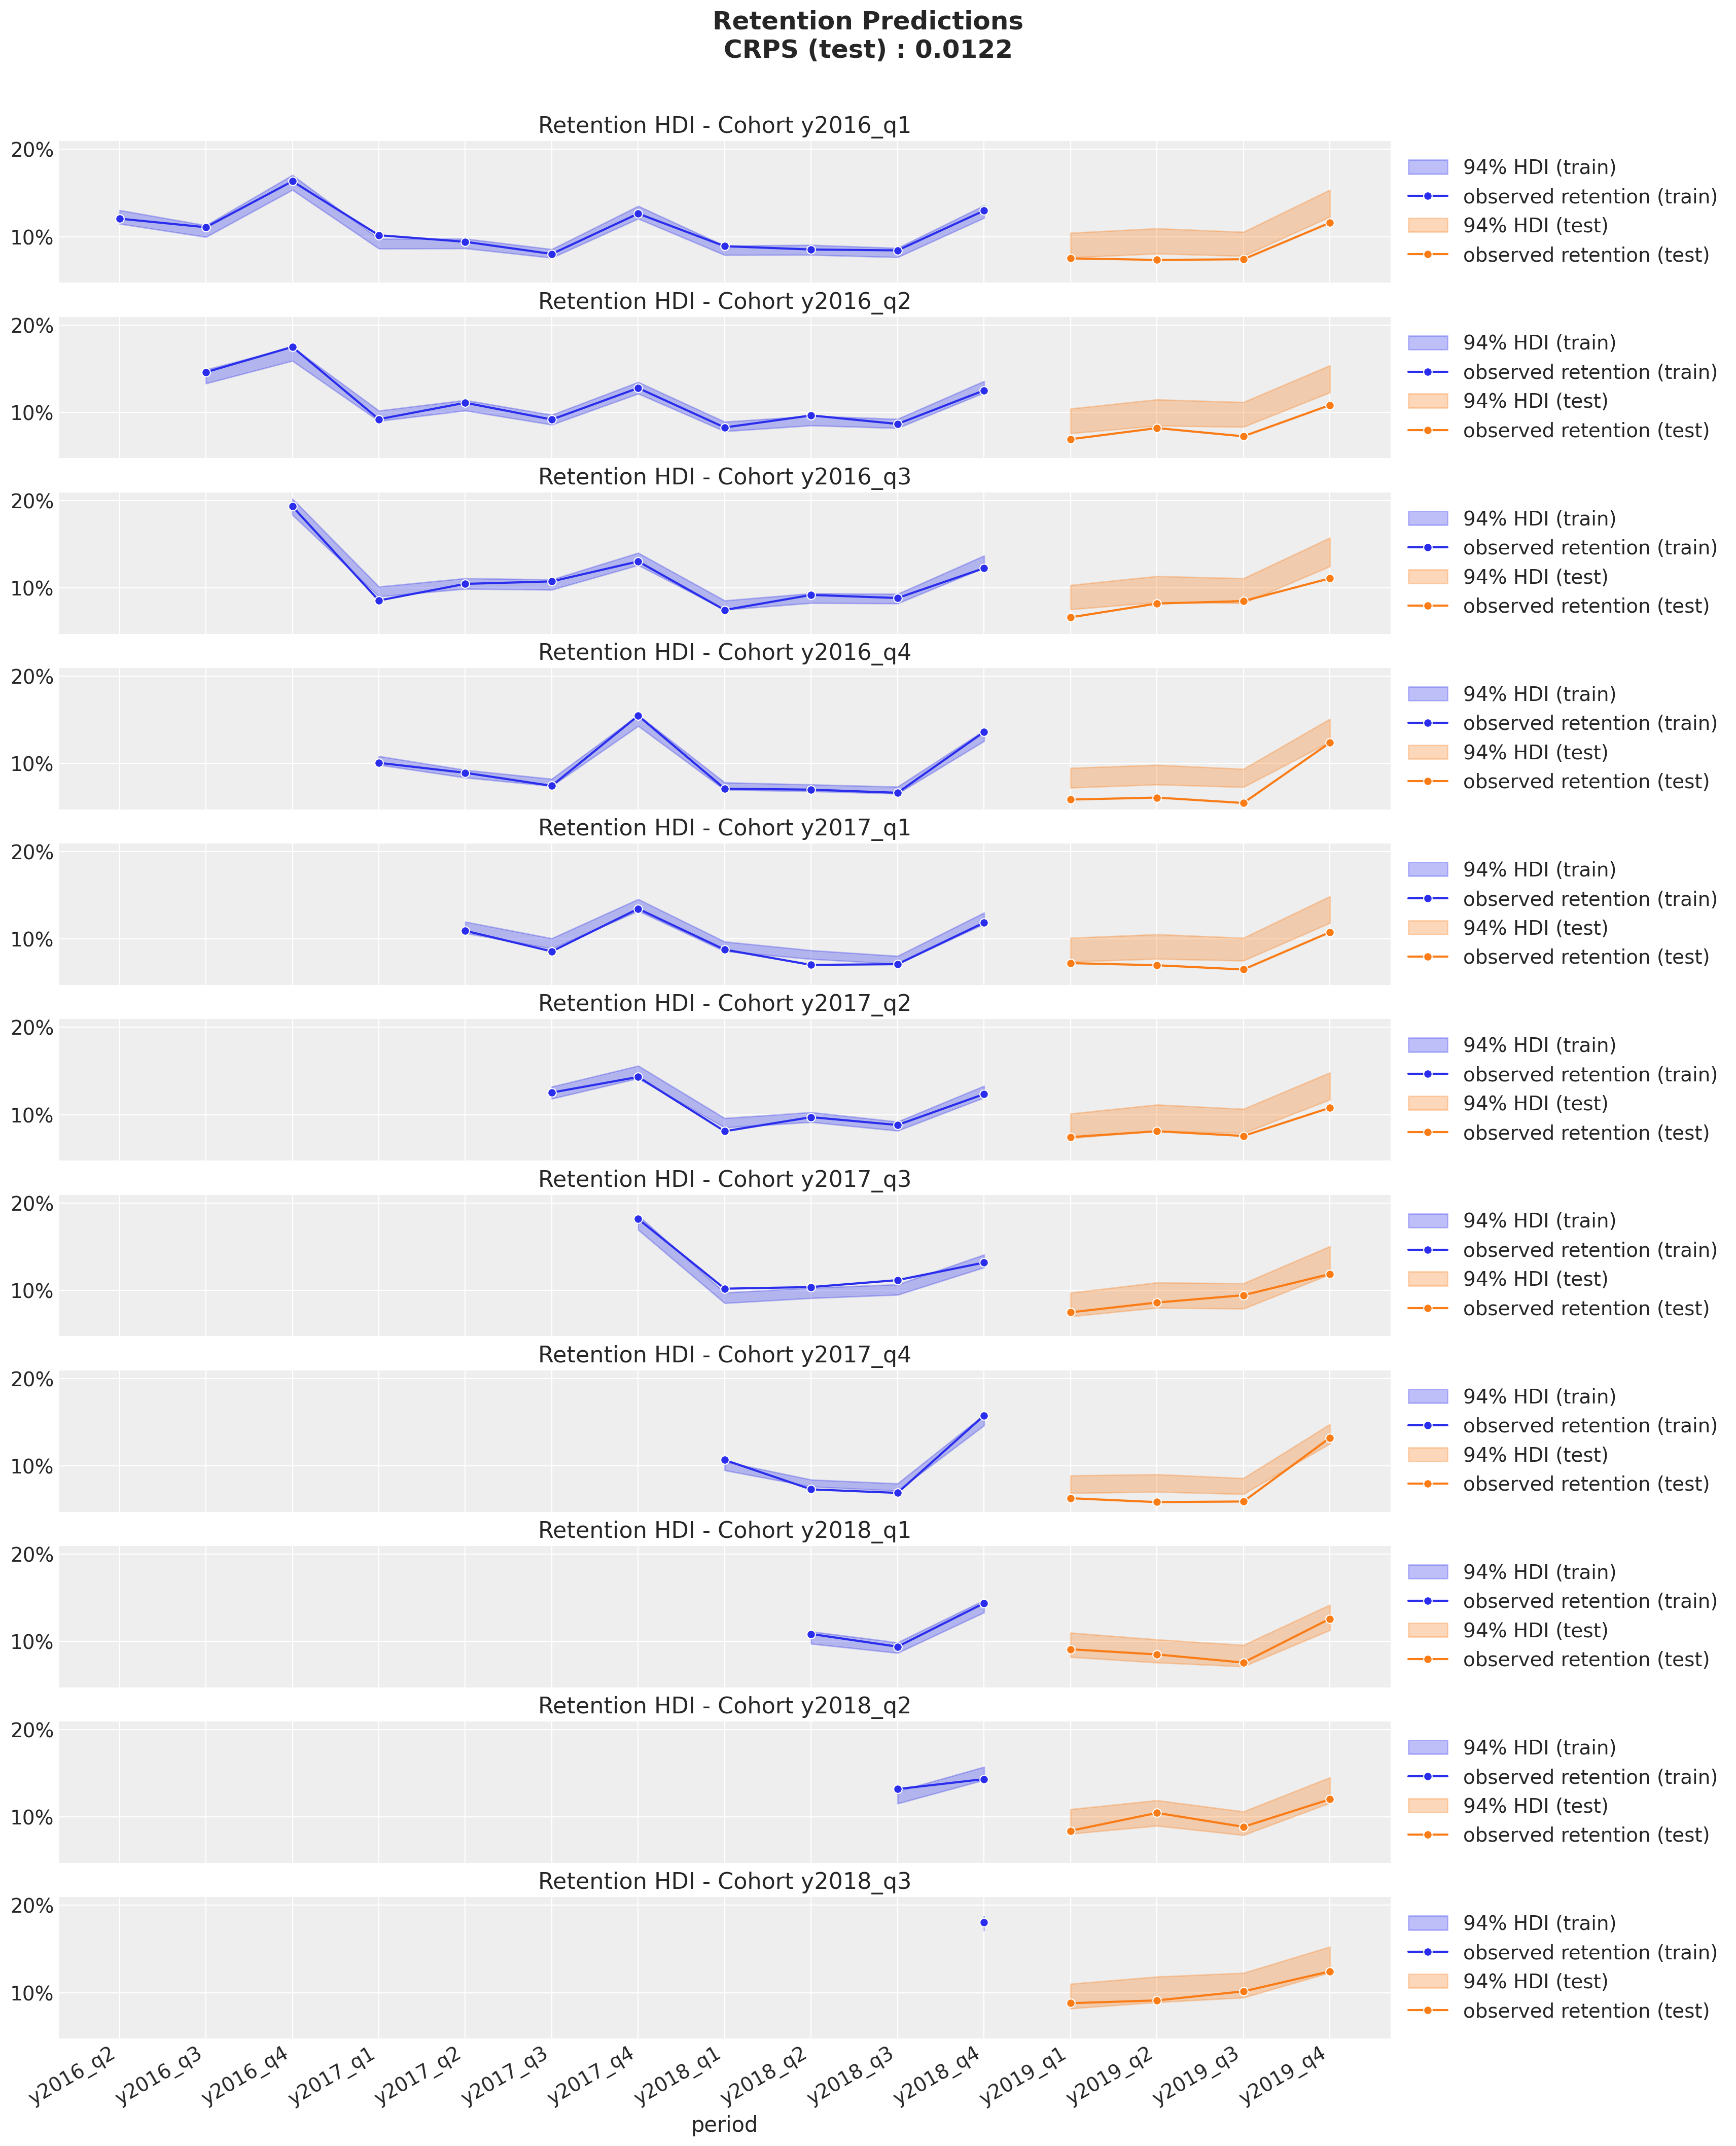

In [28]:
cohort_index_to_plot = range(train_data_df["cohort"].nunique() - 1)

fig, axes = plt.subplots(
    nrows=len(cohort_index_to_plot),
    ncols=1,
    figsize=(17, 20),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for cohort_index, ax in zip(cohort_index_to_plot, axes.flatten(), strict=True):
    plot_train_retention_hdi_cohort(cohort_index=cohort_index, ax=ax)
    plot_test_retention_hdi_cohort(cohort_index=cohort_index, ax=ax)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

retention_out_sample_crps = crps(
    y_true=test_retention,
    y_pred=az.extract(
        data=test_posterior_retention, var_names=["n_active_users_estimated"]
    ).T,
)

fig.suptitle(
    f"Retention Predictions\nCRPS (test) :{retention_out_sample_crps: .4f}",
    fontsize=18,
    fontweight="bold",
    y=1.05,
)
fig.autofmt_xdate()

For the retention predictions, the model is slightly over-estimating the retention for the older cohorts. Still, the overall trend and seasonal effects are well captured.

In [29]:
def plot_test_revenue_hdi_cohort(cohort_index: int, ax: plt.Axes) -> plt.Axes:
    mask = test_cohort_idx == cohort_index

    test_period_range = test_data_red_df.query(
        f"cohort == '{train_cohort_encoder.classes_[cohort_index]}'"
    )["period"]

    ax.fill_between(
        x=test_period_range,
        y1=test_revenue_hdi[mask, :][:, 0],
        y2=test_revenue_hdi[mask, :][:, 1],
        alpha=0.3,
        color="C1",
        label="94% HDI (test)",
    )
    sns.lineplot(
        x=test_period_range,
        y=test_revenue[mask],
        color="C1",
        marker="o",
        label="observed revenue (test)",
        ax=ax,
    )
    return ax

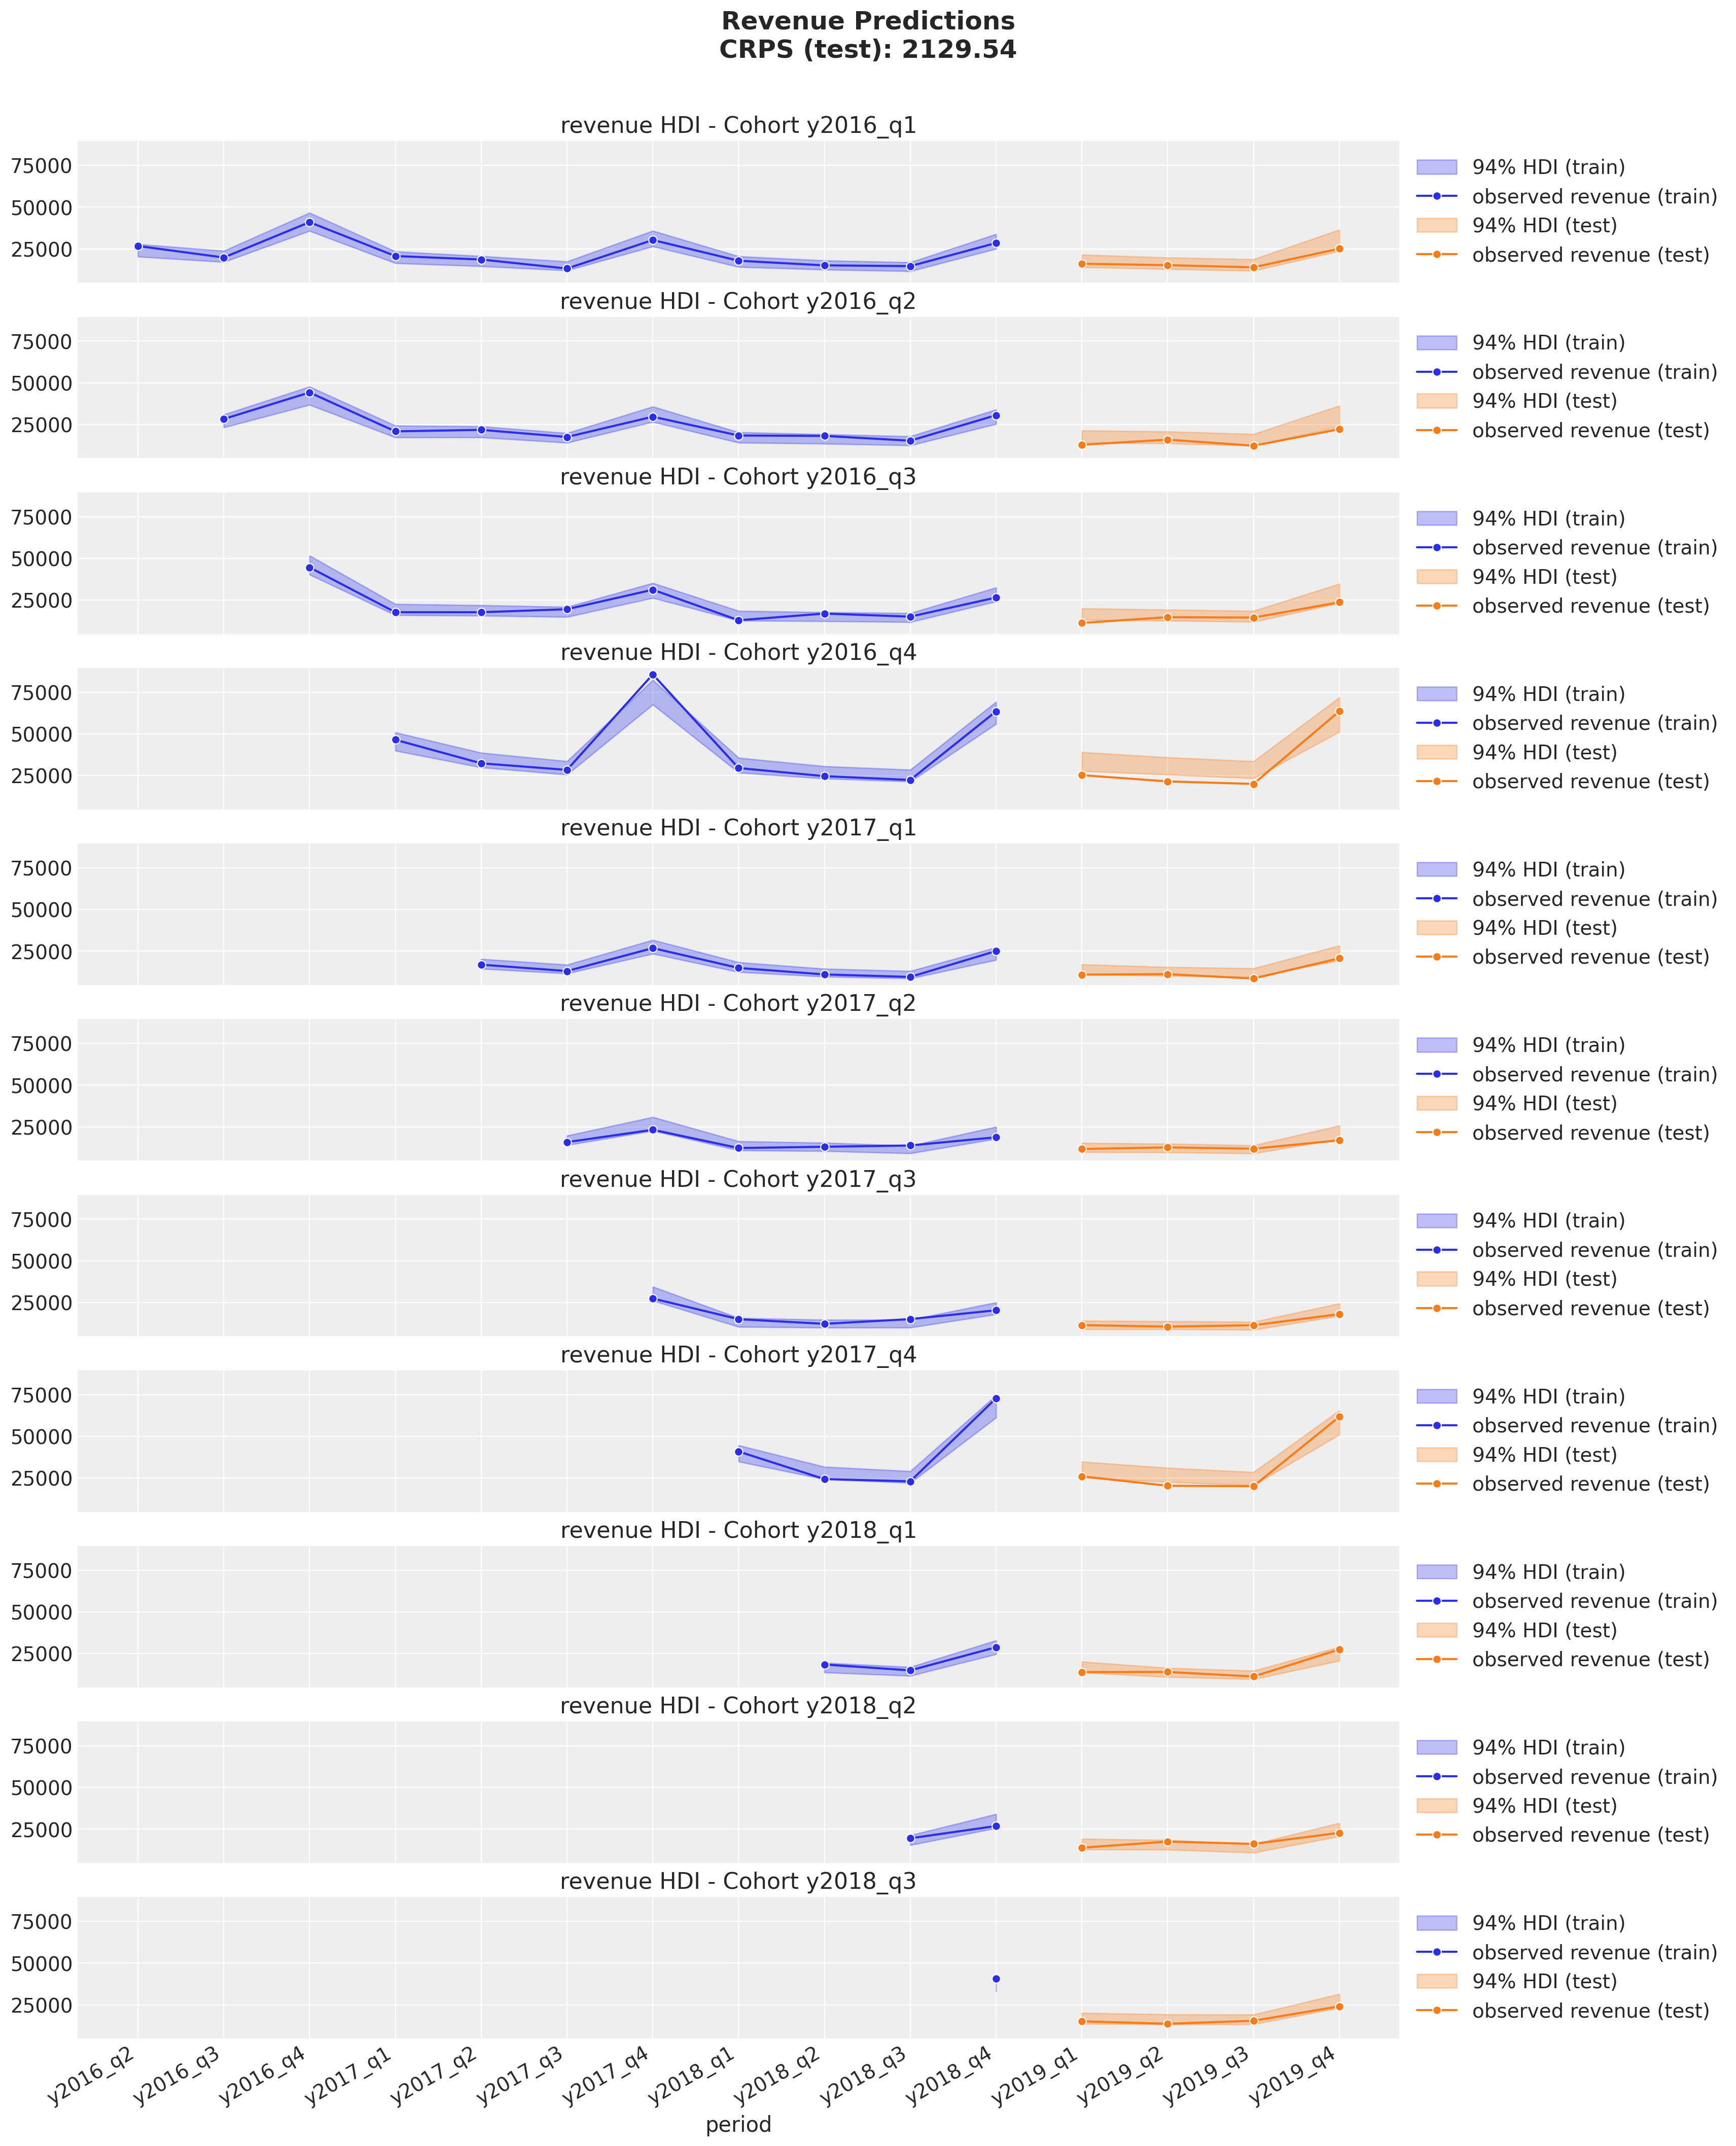

In [30]:
cohort_index_to_plot = range(train_data_df["cohort"].nunique() - 1)

fig, axes = plt.subplots(
    nrows=len(cohort_index_to_plot),
    ncols=1,
    figsize=(17, 20),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for cohort_index, ax in zip(cohort_index_to_plot, axes.flatten(), strict=True):
    plot_train_revenue_hdi_cohort(cohort_index=cohort_index, ax=ax)
    plot_test_revenue_hdi_cohort(cohort_index=cohort_index, ax=ax)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

revenue_out_sample_crps = crps(
    y_true=test_revenue,
    y_pred=az.extract(
        data=posterior_predictive_test.posterior_predictive,
        var_names=["revenue_estimated"],
    ).T,
)

fig.suptitle(
    f"Revenue Predictions\nCRPS (test):{revenue_out_sample_crps: .2f}",
    fontsize=18,
    fontweight="bold",
    y=1.05,
)
fig.autofmt_xdate()

On the other hand, the revenue predictions are much better. In particular, note how well the model performs for the youngest cohort (`y2018_q3`) with just a single data point.

In [31]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc,pytensor,pymc_bart,pymc_marketing

Last updated: Tue May 27 2025

Python implementation: CPython
Python version       : 3.12.9
IPython version      : 9.0.2

pymc          : 5.22.0
pytensor      : 2.30.3
pymc_bart     : 0.9.1
pymc_marketing: 0.13.1

numpy         : 2.1.3
pandas        : 2.2.3
matplotlib    : 3.10.1
pytensor      : 2.30.3
arviz         : 0.21.0
pymc_marketing: 0.13.1
pymc          : 5.22.0
seaborn       : 0.13.2
sklearn       : 1.6.1
pymc_bart     : 0.9.1

Watermark: 2.5.0

